# Homework 2

Done by: Vladyslav Danylyshyn and Iia Maharyta (team: Miguel)

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# from pathlib import Path
# import shutil

# source = Path("/content/drive/MyDrive/ai_hw2_workspace/results/one_stage")
# destination = Path("results/one_stage")

# if not source.exists():
#     raise FileNotFoundError(f"Не знайдено: {source}")

# destination.parent.mkdir(parents=True, exist_ok=True)
# shutil.copytree(source, destination, dirs_exist_ok=True)

# print("Copied from:", source)
# print("Copied to:", destination)

# for path in sorted(destination.rglob("*")):
#     if path.is_file():
#         print(path)

In [3]:
!pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu128
!pip install -q --upgrade-strategy only-if-needed pycocotools numpy pandas scikit-learn opencv-python pyyaml matplotlib pillow kaggle "transformers>=4.40" psutil tqdm loguru tabulate thop

import torch

print("torch:", torch.__version__)
print("torch path:", torch.__file__)
print("has torch._utils:", hasattr(torch, "_utils"))

try:
    import torchvision
    print("torchvision:", torchvision.__version__)
    print("torchvision path:", torchvision.__file__)
except Exception as exc:
    print("torchvision ERROR:", repr(exc))

try:
    import io
    buffer = io.BytesIO()
    torch.save({"x": torch.tensor([1])}, buffer)
    buffer.seek(0)
    print("torch serialization:", torch.load(buffer, weights_only=False))
except Exception as exc:
    print("torch serialization ERROR:", repr(exc))



if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. Restart the kernel and run this cell again. "
        "If it still fails, the driver is older than the cu128 wheel: change the index URL to cu124."
    )

name = torch.cuda.get_device_name(0)
vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"GPU {name}  {vram:.1f} GB")
print("packages ok")


torch: 2.14.1+cu130
torch path: /usr/local/lib/python3.13/dist-packages/torch/__init__.py
has torch._utils: True
torchvision: 0.29.1+cu130
torchvision path: /usr/local/lib/python3.13/dist-packages/torchvision/__init__.py
torch serialization: {'x': tensor([1])}
GPU NVIDIA A100-SXM4-40GB  39.5 GB
packages ok


In [4]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [5]:
import json
import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import check_random_state

IMGSZ = 1280
PAD_VALUE = 114
FRAME_STRIDE = 5  # measured in the lag cell; the loader keeps every frame
SEED = 0

cv2.setNumThreads(0)

In [6]:
!pip install -q pycocotools
from pycocotools.coco import COCO



## Data Understanding

In [7]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle").strip()

In [8]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p data
!unzip -q -o data/*.zip -d data

100% 9.88G/9.88G [09:38<00:00, 18.3MB/s]



In [9]:
ROOT = Path("data")
RESULTS = Path("results")
BOX_TOL = 1e-3


def class_names(split):
    meta = yaml.safe_load((ROOT / split / "data.yaml").read_text())
    names = meta["names"]
    if isinstance(names, dict):
        return {int(k): v for k, v in names.items()}
    return dict(enumerate(names))


def load_split(split):
    # short_line is skipped. The other counters stay in the table.
    split_dir = ROOT / split
    rows = []
    issues = {"short_line": 0, "nonpositive": 0, "out_of_range": 0, "bad_class": 0}
    for seq_dir in sorted((split_dir / "images").iterdir()):
        if not seq_dir.is_dir():
            continue
        seq = seq_dir.name
        for img_path in sorted(seq_dir.glob("*.jpg")):
            stem = img_path.stem
            label_path = split_dir / "labels" / seq / f"{stem}.txt"
            ignore_path = split_dir / "ignore" / seq / f"{stem}.txt"
            pairs = [("object", label_path), ("ignore", ignore_path)]
            any_box = False
            for kind, txt_path in pairs:
                if not txt_path.exists():
                    continue
                for line in txt_path.read_text().splitlines():
                    vals = line.split()
                    if not vals:
                        continue
                    if len(vals) < 4:
                        issues["short_line"] += 1
                        continue
                    if len(vals) == 4:
                        cls_id, cx, cy, bw, bh = None, *map(float, vals)
                    else:
                        cls_id = int(float(vals[0]))
                        cx, cy, bw, bh = map(float, vals[1:5])
                    if bw <= 0 or bh <= 0:
                        issues["nonpositive"] += 1
                    x1, y1 = cx - bw / 2, cy - bh / 2
                    x2, y2 = cx + bw / 2, cy + bh / 2
                    if (
                        min(x1, y1, cx, cy, bw, bh) < -BOX_TOL
                        or max(x2, y2, cx, cy, bw, bh) > 1 + BOX_TOL
                    ):
                        issues["out_of_range"] += 1
                    if kind == "object" and cls_id not in names:
                        issues["bad_class"] += 1
                    rows.append({
                        "split": split,
                        "sequence": seq,
                        "frame": stem,
                        "image_path": str(img_path),
                        "kind": kind,
                        "class_id": cls_id,
                        "cx": cx, "cy": cy, "w": bw, "h": bh,
                    })
                    any_box = True
            if not any_box:
                rows.append({
                    "split": split,
                    "sequence": seq,
                    "frame": stem,
                    "image_path": str(img_path),
                    "kind": "empty",
                    "class_id": None,
                    "cx": None, "cy": None, "w": None, "h": None,
                })
    return pd.DataFrame(rows), issues


names = class_names("train")
train_df, train_issues = load_split("train")
val_df, val_issues = load_split("val")

test_df = pd.read_csv(ROOT / "test_images.csv")
test_df["image_path"] = test_df["file_name"].map(lambda p: str(ROOT / p))

print("classes:", names)
print(
    "train", train_df["sequence"].nunique(), "videos,",
    train_df["image_path"].nunique(), "frames,", len(train_df), "rows",
)
print(
    "val  ", val_df["sequence"].nunique(), "videos,",
    val_df["image_path"].nunique(), "frames,", len(val_df), "rows",
)
print("test ", test_df["clip"].nunique(), "videos,", len(test_df), "frames")
print("label issues: short_line is skipped; the other rows are stored")
print("train", train_issues)
print("val", val_issues)
train_df.head()


classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}
train 56 videos, 24201 frames, 1169362 rows
val   7 videos, 2846 frames, 118127 rows
test  48 videos, 3811 frames
label issues: short_line is skipped; the other rows are stored
train {'short_line': 0, 'nonpositive': 0, 'out_of_range': 0, 'bad_class': 0}
val {'short_line': 0, 'nonpositive': 0, 'out_of_range': 0, 'bad_class': 0}


,split,sequence,frame,image_path,kind,class_id,cx,cy,w,h
0,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.328497,0.776455,0.026042,0.116402
1,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.322917,0.757275,0.026786,0.112434
2,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,5.0,0.427455,0.923280,0.064732,0.150794
3,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.451637,0.610450,0.023810,0.104497
4,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.345610,0.578042,0.015625,0.063492


TRAIN
class_name  boxes    share
       car 505301 0.457073
    person 328701 0.297328
     motor 102819 0.093005
       van  46940 0.042460
  tricycle  41349 0.037402
   bicycle  40255 0.036413
     truck  30498 0.027587
       bus   9653 0.008732

VAL
class_name  boxes    share
    person  50312 0.440823
       car  31821 0.278809
     motor  12025 0.105360
       van   6842 0.059948
   bicycle   6022 0.052763
  tricycle   5487 0.048076
     truck   1359 0.011907
       bus    264 0.002313


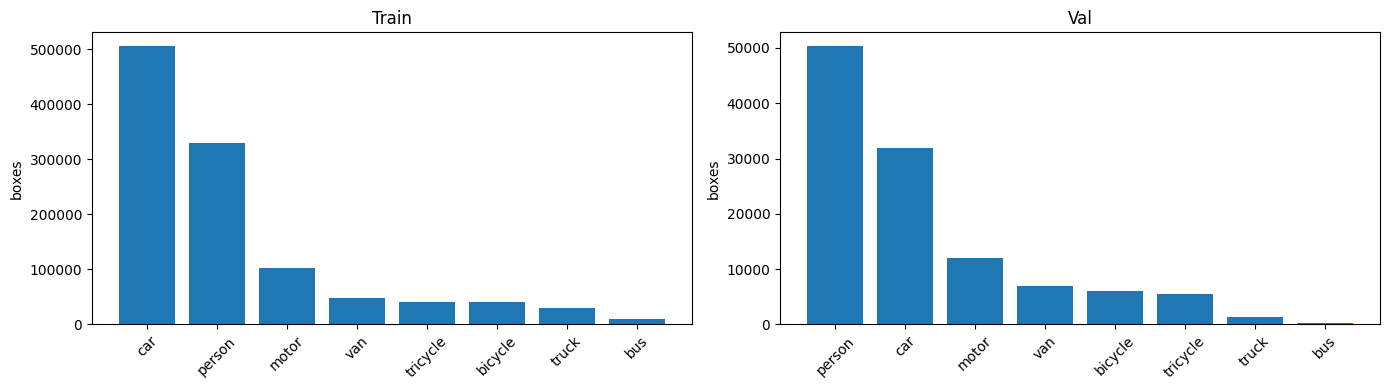

In [10]:
def class_counts(df):
    objects = df[df["kind"] == "object"].copy()
    objects["class_name"] = objects["class_id"].map(names)
    counts = (
        objects["class_name"]
        .value_counts()
        .rename_axis("class_name")
        .reset_index(name="boxes")
    )
    counts["share"] = counts["boxes"] / counts["boxes"].sum()
    return objects, counts

train_obj, train_class_counts = class_counts(train_df)
val_obj, val_class_counts = class_counts(val_df)
print("TRAIN")
print(train_class_counts.to_string(index=False))
print("\nVAL")
print(val_class_counts.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, counts, title in (
    (axes[0], train_class_counts, "Train"),
    (axes[1], val_class_counts, "Val"),
):
    ax.bar(counts["class_name"], counts["boxes"])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("boxes")
fig.tight_layout()
plt.show()


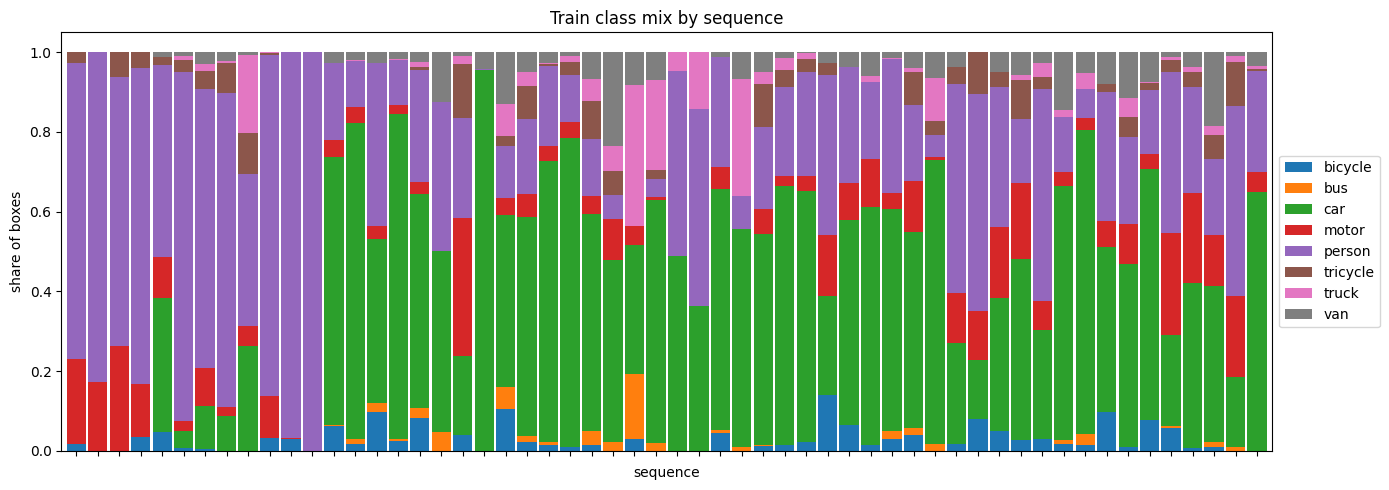

dominant-class share within a sequence: min 34.6%, max 100.0%
highest share


,class_name,share
sequence,,
uav0000099_02109_v,person,1.000000
uav0000084_00000_v,person,0.969004
uav0000218_00001_v,car,0.954231
uav0000072_04488_v,person,0.874654
uav0000079_00480_v,person,0.855673
uav0000013_01073_v,person,0.827017
uav0000140_01590_v,car,0.815347
uav0000020_00406_v,person,0.793354


lowest share


,class_name,share
sequence,,
uav0000361_02323_v,car,0.393167
uav0000076_00720_v,person,0.381220
uav0000263_03289_v,truck,0.354247
uav0000309_00000_v,person,0.350711
uav0000150_02310_v,motor,0.346062


sequences with a single class: 1


,class_name,share
sequence,,
uav0000099_02109_v,person,1.0


sequences with no object boxes: []
sequences whose object rows have no known class: []


In [11]:
per_seq = (
    train_obj.groupby(["sequence", "class_name"])
    .size()
    .unstack(fill_value=0)
)
per_seq_share = per_seq.div(per_seq.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(14, 5))
per_seq_share.plot(kind="bar", stacked=True, ax=ax, width=0.9)
ax.set_title("Train class mix by sequence")
ax.set_ylabel("share of boxes")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_xticklabels([])
fig.tight_layout()
plt.show()

dominant = pd.DataFrame({
    "class_name": per_seq_share.idxmax(axis=1),
    "share": per_seq_share.max(axis=1),
}).sort_values("share", ascending=False)
print(
    "dominant-class share within a sequence: "
    f"min {dominant['share'].min():.1%}, max {dominant['share'].max():.1%}"
)
print("highest share")
display(dominant.head(8))
print("lowest share")
display(dominant.tail(5))
pure = dominant[dominant["share"] >= 1 - 1e-9]
print(f"sequences with a single class: {len(pure)}")
display(pure)
object_sequences = set(train_df.loc[train_df["kind"] == "object", "sequence"])
named_sequences = set(per_seq_share.index)
print("sequences with no object boxes:", sorted(set(train_df["sequence"]) - object_sequences))
print("sequences whose object rows have no known class:", sorted(object_sequences - named_sequences))


In [12]:
def read_size(path):
    with Image.open(path) as im:
        return im.size


def frame_sizes(df):
    frames = (
        df.drop_duplicates(["sequence", "frame"])
        [["sequence", "frame", "image_path"]]
        .reset_index(drop=True)
    )
    wh = [read_size(path) for path in frames["image_path"]]
    frames["img_w"] = [w for w, h in wh]
    frames["img_h"] = [h for w, h in wh]
    return frames


def resolution_report(frames, title):
    mixed = int((
        frames.groupby("sequence")[["img_w", "img_h"]].nunique().max(axis=1) > 1
    ).sum())
    counts = (
        frames.groupby(["img_w", "img_h"])
        .size()
        .rename("frames")
        .reset_index()
        .sort_values("frames", ascending=False)
    )
    print(title)
    print(f"sequences with more than one resolution: {mixed}")
    display(counts)
    return counts, mixed


def with_pixel_size(df, sizes):
    objects = df[df["kind"] == "object"].merge(
        sizes[["sequence", "frame", "img_w", "img_h"]],
        on=["sequence", "frame"],
        how="left",
    )
    objects["class_name"] = objects["class_id"].map(names)
    objects["box_w"] = objects["w"] * objects["img_w"]
    objects["box_h"] = objects["h"] * objects["img_h"]
    objects["area"] = objects["box_w"] * objects["box_h"]
    return objects


def per_frame_counts(df):
    frames = df.drop_duplicates(["sequence", "frame"])[["sequence", "frame"]]
    counts = (
        df[df["kind"] == "object"]
        .groupby(["sequence", "frame"])
        .size()
        .rename("n_objects")
        .reset_index()
    )
    return frames.merge(counts, on=["sequence", "frame"], how="left").fillna({"n_objects": 0})


train_frame_sizes = frame_sizes(train_df)
val_frame_sizes = frame_sizes(val_df)
resolution_report(train_frame_sizes, "TRAIN resolutions")
resolution_report(val_frame_sizes, "VAL resolutions")
train_boxes = with_pixel_size(train_df, train_frame_sizes)
val_boxes = with_pixel_size(val_df, val_frame_sizes)
train_frame_counts = per_frame_counts(train_df)
val_frame_counts = per_frame_counts(val_df)


TRAIN resolutions
sequences with more than one resolution: 0


,img_w,img_h,frames
2,1904,1071,12895
0,1344,756,5645
4,2688,1512,3505
1,1360,765,962
3,1920,1080,721
5,2720,1530,473


VAL resolutions
sequences with more than one resolution: 0


,img_w,img_h,frames
4,3840,2160,978
0,1344,756,827
1,1904,1071,459
3,2720,1530,349
2,2688,1512,233



TRAIN native pixels
width  px: median 44, p10 19, p90 126
height px: median 48, p10 25, p90 97
area bins: small 24.9%, medium 63.5%, large 11.6%
objects/frame: median 43, mean 45.7, max 180

VAL native pixels
width  px: median 47, p10 20, p90 110
height px: median 57, p10 29, p90 116
area bins: small 19.2%, medium 69.5%, large 11.3%
objects/frame: median 37, mean 40.1, max 116
train frame with the most objects: uav0000295_02300_v 0000322 n=180
spearman mean objects/frame vs median box area: -0.008
densest sequences


,median,mean,max,median_area
sequence,,,,
uav0000138_00000_v,150.0,142.962441,156.0,2059.073456
uav0000126_00001_v,130.0,132.218447,166.0,2340.021696
uav0000124_00944_v,129.0,124.567839,134.0,2145.001127
uav0000072_04488_v,108.0,110.376471,124.0,2099.944350
uav0000150_02310_v,102.0,108.885057,174.0,3603.988592


sparsest sequences


,median,mean,max,median_area
sequence,,,,
uav0000099_02109_v,7.0,7.135458,13.0,1374.979820
uav0000266_03598_v,6.0,6.474453,10.0,6548.412416
uav0000263_03289_v,7.0,6.463448,11.0,3008.958639
uav0000266_04830_v,6.0,6.086207,7.0,6655.911424
uav0000218_00001_v,5.0,5.146667,7.0,3861.547948


native aspect w/h p10, p50, p90: 0.44 0.95 2.13

TEST
clips 48, frames 3811
frames/clip: median 74, mean 79.4, max 148
frames at each resolution


,img_w,img_h,frames
3,1360,764,1474
5,1920,1080,991
2,1344,756,441
0,680,382,321
4,1904,1072,305
1,960,540,279


no boxes: test labels are not provided


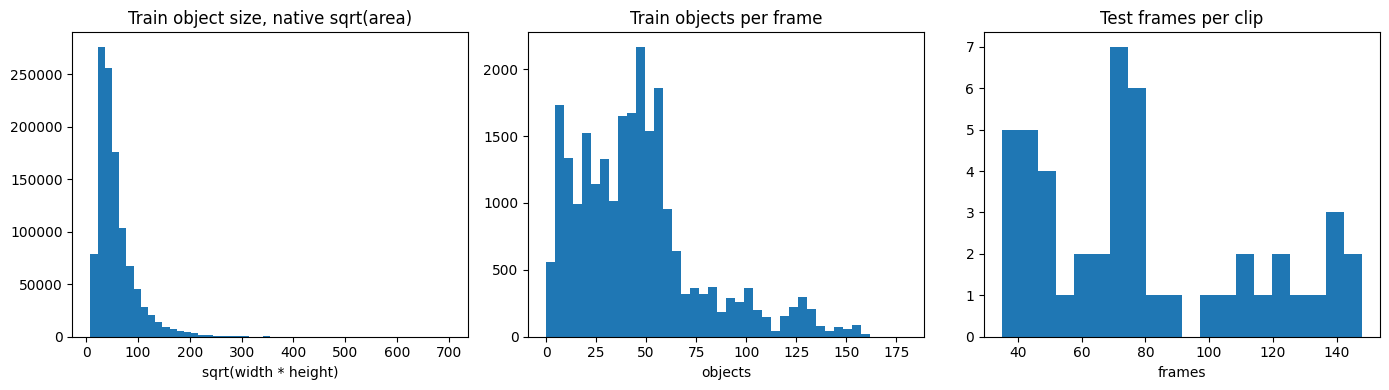

In [13]:
def print_box_size(width, height, area, title):
    print(title)
    print(
        f"width  px: median {width.median():.0f}, "
        f"p10 {width.quantile(.1):.0f}, p90 {width.quantile(.9):.0f}"
    )
    print(
        f"height px: median {height.median():.0f}, "
        f"p10 {height.quantile(.1):.0f}, p90 {height.quantile(.9):.0f}"
    )
    small = float((area < 32 ** 2).mean())
    medium = float(((area >= 32 ** 2) & (area < 96 ** 2)).mean())
    large = float((area >= 96 ** 2).mean())
    print(f"area bins: small {small:.1%}, medium {medium:.1%}, large {large:.1%}")
    return small, medium, large


def summarize(boxes, counts, title):
    print_box_size(boxes["box_w"], boxes["box_h"], boxes["area"], f"\n{title} native pixels")
    print(
        f"objects/frame: median {counts.n_objects.median():.0f}, "
        f"mean {counts.n_objects.mean():.1f}, max {counts.n_objects.max():.0f}"
    )


summarize(train_boxes, train_frame_counts, "TRAIN")
summarize(val_boxes, val_frame_counts, "VAL")
peak = train_frame_counts.loc[train_frame_counts["n_objects"].idxmax()]
print(
    "train frame with the most objects: "
    f"{peak.sequence} {peak.frame} n={peak.n_objects:.0f}"
)

by_seq = train_frame_counts.groupby("sequence")["n_objects"].agg(["median", "mean", "max"])
by_seq["median_area"] = train_boxes.groupby("sequence")["area"].median()
by_seq = by_seq.dropna(subset=["median_area"]).sort_values("mean", ascending=False)
corr = by_seq["mean"].corr(by_seq["median_area"], method="spearman")
print(f"spearman mean objects/frame vs median box area: {corr:.3f}")
print("densest sequences")
display(by_seq.head(5))
print("sparsest sequences")
display(by_seq.tail(5))

aspect = train_boxes["box_w"] / train_boxes["box_h"].clip(lower=1)
print(
    "native aspect w/h p10, p50, p90:",
    f"{aspect.quantile(0.1):.2f}",
    f"{aspect.median():.2f}",
    f"{aspect.quantile(0.9):.2f}",
)

test_per_clip = test_df.groupby("clip").size()
test_wh = [read_size(path) for path in test_df["image_path"]]
test_sizes = test_df[["clip"]].copy()
test_sizes["img_w"] = [w for w, h in test_wh]
test_sizes["img_h"] = [h for w, h in test_wh]
print("\nTEST")
print(f"clips {test_df['clip'].nunique()}, frames {len(test_df)}")
print(
    f"frames/clip: median {test_per_clip.median():.0f}, "
    f"mean {test_per_clip.mean():.1f}, max {test_per_clip.max():.0f}"
)
print("frames at each resolution")
display(
    test_sizes.groupby(["img_w", "img_h"])
    .size()
    .rename("frames")
    .reset_index()
    .sort_values("frames", ascending=False)
)
print("no boxes: test labels are not provided")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(np.sqrt(train_boxes["area"].clip(lower=0)), bins=50)
axes[0].set_title("Train object size, native sqrt(area)")
axes[0].set_xlabel("sqrt(width * height)")
axes[1].hist(train_frame_counts["n_objects"], bins=40)
axes[1].set_title("Train objects per frame")
axes[1].set_xlabel("objects")
axes[2].hist(test_per_clip, bins=20)
axes[2].set_title("Test frames per clip")
axes[2].set_xlabel("frames")
fig.tight_layout()
plt.show()


In [14]:
def coverage(df, title):
    frames = df.drop_duplicates(["sequence", "frame"])
    object_keys = set(zip(
        df.loc[df["kind"] == "object", "sequence"],
        df.loc[df["kind"] == "object", "frame"],
    ))
    all_keys = set(zip(frames["sequence"], frames["frame"]))
    ignore = df[df["kind"] == "ignore"]
    ignore_frames = ignore.drop_duplicates(["sequence", "frame"])
    print(title)
    print(f"frames {len(frames)}")
    print(f"frames with no object boxes {len(all_keys - object_keys)}")
    print(f"frames with no boxes at all {int((df['kind'] == 'empty').sum())}")
    print(f"ignore boxes {len(ignore)} on {len(ignore_frames)} frames")


coverage(train_df, "TRAIN coverage")
coverage(val_df, "VAL coverage")


TRAIN coverage
frames 24201
frames with no object boxes 3
frames with no boxes at all 3
ignore boxes 63843 on 18090 frames
VAL coverage
frames 2846
frames with no object boxes 0
frames with no boxes at all 0
ignore boxes 3995 on 1434 frames


In [15]:
def valid_class_id(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    try:
        parsed = int(value)
    except (TypeError, ValueError):
        return None
    if parsed not in names:
        return None
    return parsed


def build_coco(df, sizes, split):
    # area is the original-frame box. Letterbox size is a separate table.
    ignore_id = int(max(names) + 1)
    frames = sizes[["sequence", "frame", "img_w", "img_h"]].reset_index(drop=True)
    images = []
    image_ids = {}
    for image_id, row in enumerate(frames.itertuples(index=False), start=1):
        image_ids[(row.sequence, row.frame)] = image_id
        images.append({
            "id": image_id,
            "file_name": f"{split}/images/{row.sequence}/{row.frame}.jpg",
            "width": int(row.img_w),
            "height": int(row.img_h),
            "sequence": row.sequence,
            "frame": str(row.frame),
        })
    labeled = df[df["kind"].isin(["object", "ignore"])].merge(
        frames, on=["sequence", "frame"], how="left",
    )
    annotations = []
    skipped = 0
    for row in labeled.itertuples(index=False):
        if row.kind == "object":
            category_id = valid_class_id(row.class_id)
            if category_id is None:
                skipped += 1
                continue
            iscrowd = 0
        else:
            category_id = ignore_id
            iscrowd = 1
        bw = float(row.w) * int(row.img_w)
        bh = float(row.h) * int(row.img_h)
        annotations.append({
            "id": len(annotations) + 1,
            "image_id": image_ids[(row.sequence, row.frame)],
            "category_id": category_id,
            "bbox": [
                (float(row.cx) - float(row.w) / 2.0) * int(row.img_w),
                (float(row.cy) - float(row.h) / 2.0) * int(row.img_h),
                bw,
                bh,
            ],
            "area": float(bw * bh),
            "iscrowd": iscrowd,
        })
    categories = [
        {"id": int(class_id), "name": class_name}
        for class_id, class_name in sorted(names.items())
    ]
    categories.append({"id": ignore_id, "name": "ignore"})
    dataset = {
        "info": {"description": f"{split} boxes in original-frame pixels", "year": 2026},
        "licenses": [],
        "images": images,
        "annotations": annotations,
        "categories": categories,
    }
    path = ROOT / "annotations" / f"instances_{split}.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as handle:
        json.dump(dataset, handle, separators=(",", ":"))
    print(
        f"{path} images {len(images)} annotations {len(annotations)} "
        f"skipped_bad_objects {skipped} ignore_category {ignore_id}"
    )
    return path


def print_coco_bins(coco):
    # pycocotools keeps a box when low < area < high. Bounds are strict.
    object_ids = coco.getAnnIds(iscrowd=0)
    ignore_ids = coco.getAnnIds(iscrowd=1)
    print(f"objects {len(object_ids)}  ignore {len(ignore_ids)}  images {len(coco.imgs)}")
    ranges = (
        ("small", [0, 32 ** 2]),
        ("medium", [32 ** 2, 96 ** 2]),
        ("large", [96 ** 2, 1e5 ** 2]),
    )
    for label, area_rng in ranges:
        n = len(coco.getAnnIds(iscrowd=0, areaRng=area_rng))
        share = n / len(object_ids) if object_ids else float("nan")
        print(f"  {label} {area_rng[0]:.0f} < area < {area_rng[1]:.0f}: {n} ({share:.1%})")
    for cat in coco.dataset["categories"]:
        crowd = 1 if cat["name"] == "ignore" else 0
        n = len(coco.getAnnIds(catIds=[cat["id"]], iscrowd=crowd))
        print(f"  category {cat['id']} {cat['name']}: {n}")


train_coco_path = build_coco(train_df, train_frame_sizes, "train")
val_coco_path = build_coco(val_df, val_frame_sizes, "val")
print("TRAIN coco, native pixels")
print_coco_bins(COCO(str(train_coco_path)))
print("VAL coco, native pixels")
print_coco_bins(COCO(str(val_coco_path)))


data/annotations/instances_train.json images 24201 annotations 1169359 skipped_bad_objects 0 ignore_category 8
data/annotations/instances_val.json images 2846 annotations 118127 skipped_bad_objects 0 ignore_category 8
TRAIN coco, native pixels
loading annotations into memory...
Done (t=3.80s)
creating index...
index created!
objects 1105516  ignore 63843  images 24201
  small 0 < area < 1024: 275368 (24.9%)
  medium 1024 < area < 9216: 702031 (63.5%)
  large 9216 < area < 10000000000: 128117 (11.6%)
  category 0 person: 328701
  category 1 bicycle: 40255
  category 2 car: 505301
  category 3 van: 46940
  category 4 truck: 30498
  category 5 tricycle: 41349
  category 6 bus: 9653
  category 7 motor: 102819
  category 8 ignore: 63843
VAL coco, native pixels
loading annotations into memory...
Done (t=0.34s)
creating index...
index created!
objects 114132  ignore 3995  images 2846
  small 0 < area < 1024: 21918 (19.2%)
  medium 1024 < area < 9216: 79351 (69.5%)
  large 9216 < area < 100000

Letterbox scales every box by side / native long side.
A side of 640 is half the linear size of a side of 1280.
Area bins here are small < 32^2 <= medium < 96^2 <= large.

TRAIN at 1280
width  px: median 30, p10 13, p90 79
height px: median 32, p10 16, p90 64
area bins: small 54.2%, medium 42.8%, large 3.0%

TRAIN at 640
width  px: median 15, p10 6, p90 40
height px: median 16, p10 8, p90 32
area bins: small 89.0%, medium 10.9%, large 0.1%

VAL at 1280
width  px: median 28, p10 15, p90 68
height px: median 37, p10 16, p90 74
area bins: small 48.4%, medium 49.7%, large 2.0%

TRAIN at 1280 by native resolution


,img_w,img_h,boxes,median_w,median_h,small_share
2,1904,1071,593183,30.92480,33.61320,0.497708
4,2688,1512,230795,28.57088,25.23816,0.631526
0,1344,756,155031,27.61856,37.14264,0.521328
1,1360,765,52919,32.94080,27.29376,0.552240
3,1920,1080,40928,26.00064,23.99976,0.674844
5,2720,1530,32660,22.11712,32.47056,0.622352


VAL at 1280 by native resolution


,img_w,img_h,boxes,median_w,median_h,small_share
0,1344,756,40768,29.52320,40.00032,0.414614
2,2688,1512,24088,32.38144,38.57112,0.385130
1,1904,1071,18419,33.61408,37.64736,0.416038
3,2720,1530,17279,24.00000,40.47048,0.567857
4,3840,2160,13578,19.66720,12.33360,0.850567


TRAIN median width, height, aspect at 1280


,boxes,median_w,median_h,median_aspect
class_name,,,,
car,505301,41.68064,30.92472,1.249966
person,328701,18.09536,33.61320,0.500021
motor,102819,24.76160,27.56304,0.803927
van,46940,37.64736,32.38128,1.109077
tricycle,41349,40.00000,35.62992,1.064516
bicycle,40255,25.71392,26.66664,0.947389
truck,30498,53.78176,44.37000,1.076932
bus,9653,81.90464,56.47032,1.033320


VAL median width, height, aspect at 1280


,boxes,median_w,median_h,median_aspect
class_name,,,,
person,50312,22.11712,43.80984,0.494731
car,31821,38.31936,30.00024,1.380949
motor,12025,26.35264,30.47616,0.850014
van,6842,43.80928,34.76160,1.205020
bicycle,6022,32.38144,39.52368,0.833315
tricycle,5487,35.23840,40.00032,0.999964
truck,1359,58.09536,44.76168,1.592604
bus,264,92.77312,43.02504,2.341118


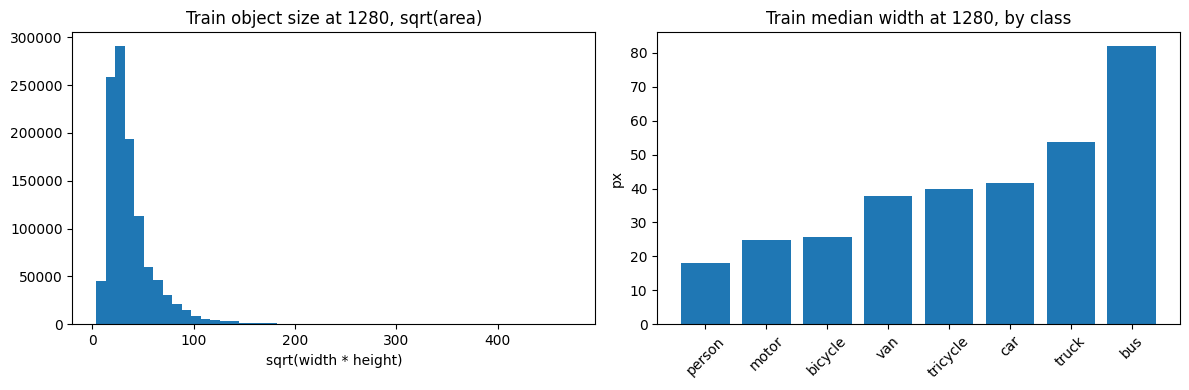

In [16]:
def add_letterbox_size(objects, new_shape):
    # Matches letterbox(): box width scales by new_shape / max(img_w, img_h).
    out = objects.copy()
    img_w = out["img_w"].to_numpy(dtype=np.float64)
    img_h = out["img_h"].to_numpy(dtype=np.float64)
    ratio = new_shape / np.maximum(img_w, img_h)
    out["lb_w"] = out["w"].to_numpy(dtype=np.float64) * img_w * ratio
    out["lb_h"] = out["h"].to_numpy(dtype=np.float64) * img_h * ratio
    out["lb_area"] = out["lb_w"] * out["lb_h"]
    return out


def size_by_class(objects):
    aspect = objects["lb_w"] / objects["lb_h"].clip(lower=1e-6)
    return (
        objects.assign(aspect=aspect)
        .groupby("class_name")
        .agg(
            boxes=("aspect", "size"),
            median_w=("lb_w", "median"),
            median_h=("lb_h", "median"),
            median_aspect=("aspect", "median"),
        )
        .sort_values("boxes", ascending=False)
    )


def size_by_resolution(objects):
    return (
        objects.groupby(["img_w", "img_h"])
        .agg(
            boxes=("lb_w", "size"),
            median_w=("lb_w", "median"),
            median_h=("lb_h", "median"),
            small_share=("lb_area", lambda area: float((area < 32 ** 2).mean())),
        )
        .reset_index()
        .sort_values("boxes", ascending=False)
    )


print("Letterbox scales every box by side / native long side.")
print("A side of 640 is half the linear size of a side of 1280.")
print("Area bins here are small < 32^2 <= medium < 96^2 <= large.")
train_at_1280 = add_letterbox_size(train_boxes, IMGSZ)
train_at_640 = add_letterbox_size(train_boxes, 640)
val_at_1280 = add_letterbox_size(val_boxes, IMGSZ)
print_box_size(train_at_1280["lb_w"], train_at_1280["lb_h"], train_at_1280["lb_area"], "\nTRAIN at 1280")
print_box_size(train_at_640["lb_w"], train_at_640["lb_h"], train_at_640["lb_area"], "\nTRAIN at 640")
print_box_size(val_at_1280["lb_w"], val_at_1280["lb_h"], val_at_1280["lb_area"], "\nVAL at 1280")
print("\nTRAIN at 1280 by native resolution")
display(size_by_resolution(train_at_1280))
print("VAL at 1280 by native resolution")
display(size_by_resolution(val_at_1280))
train_by_class = size_by_class(train_at_1280)
val_by_class = size_by_class(val_at_1280)
print("TRAIN median width, height, aspect at 1280")
display(train_by_class)
print("VAL median width, height, aspect at 1280")
display(val_by_class)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.sqrt(train_at_1280["lb_area"].clip(lower=0)), bins=50)
axes[0].set_title("Train object size at 1280, sqrt(area)")
axes[0].set_xlabel("sqrt(width * height)")
order = train_by_class.sort_values("median_w")
axes[1].bar(order.index.astype(str), order["median_w"])
axes[1].set_title("Train median width at 1280, by class")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylabel("px")
fig.tight_layout()
plt.show()


In [17]:
def frame_sort_key(stem):
    text = str(stem)
    if text.isdigit():
        return (0, int(text))
    return (1, text)


def pairwise_iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[:, :, 0] * wh[:, :, 1]
    area_a = np.clip(a[:, 2] - a[:, 0], 0, None) * np.clip(a[:, 3] - a[:, 1], 0, None)
    area_b = np.clip(b[:, 2] - b[:, 0], 0, None) * np.clip(b[:, 3] - b[:, 1], 0, None)
    union = area_a[:, None] + area_b[None, :] - inter
    return np.where(union > 0, inter / union, 0.0)


def match_fraction(a, b, thr=0.5):
    # Share of the larger set that has a greedy match at IoU >= thr.
    if len(a) == 0 and len(b) == 0:
        return None
    if len(a) == 0 or len(b) == 0:
        return 0.0
    iou = pairwise_iou(a, b)
    matched = 0
    while True:
        index = np.unravel_index(np.argmax(iou), iou.shape)
        if iou[index] < thr:
            break
        matched += 1
        iou[index[0], :] = -1
        iou[:, index[1]] = -1
    return matched / max(len(a), len(b))


def lag_report(df, lags, title):
    print(title)
    print(f"FRAME_STRIDE={FRAME_STRIDE} is not applied. Pairing stored frames.")
    objects = df.loc[df["kind"] == "object", ["sequence", "frame", "cx", "cy", "w", "h"]]
    grouped = {}
    for (seq, frame), group in objects.groupby(["sequence", "frame"], sort=False):
        cx = group["cx"].to_numpy(dtype=np.float64)
        cy = group["cy"].to_numpy(dtype=np.float64)
        w = group["w"].to_numpy(dtype=np.float64)
        h = group["h"].to_numpy(dtype=np.float64)
        grouped[(seq, frame)] = np.stack(
            [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1,
        )
    frames = df.drop_duplicates(["sequence", "frame"])[["sequence", "frame"]]
    for lag in lags:
        scores = []
        both_empty = 0
        for seq, group in frames.groupby("sequence", sort=False):
            ordered = sorted(group["frame"].tolist(), key=frame_sort_key)
            for i in range(len(ordered) - lag):
                a = grouped.get((seq, ordered[i]))
                b = grouped.get((seq, ordered[i + lag]))
                if a is None and b is None:
                    both_empty += 1
                    continue
                if a is None:
                    a = np.zeros((0, 4))
                if b is None:
                    b = np.zeros((0, 4))
                scores.append(match_fraction(a, b))
        arr = np.asarray(scores, dtype=np.float64)
        if len(arr) == 0:
            print(f"lag {lag}: pairs 0, both empty skipped {both_empty}")
            continue
        print(
            f"lag {lag}: pairs {len(arr)}, both empty skipped {both_empty}, "
            f"matched at IoU>=0.5 median {np.median(arr):.3f}, mean {arr.mean():.3f}"
        )


lag_report(train_df, (1, FRAME_STRIDE), "TRAIN frame agreement")
lag_report(val_df, (1, FRAME_STRIDE), "VAL frame agreement")


TRAIN frame agreement
FRAME_STRIDE=5 is not applied. Pairing stored frames.
lag 1: pairs 24143, both empty skipped 2, matched at IoU>=0.5 median 0.990, mean 0.943
lag 5: pairs 23921, both empty skipped 0, matched at IoU>=0.5 median 0.597, mean 0.551
VAL frame agreement
FRAME_STRIDE=5 is not applied. Pairing stored frames.
lag 1: pairs 2839, both empty skipped 0, matched at IoU>=0.5 median 0.929, mean 0.865
lag 5: pairs 2811, both empty skipped 0, matched at IoU>=0.5 median 0.600, mean 0.540


Class mix, object size, and frame density belong to a whole video, not to a single frame. Figures quoted here were printed by the previous run of the class table and the native-size summary. Every other result is printed by the cells above and is not copied into this text.

**Classes.** Train boxes are 45.7% car, 29.7% person, 9.3% motor, then van 4.2%, tricycle 3.7%, bicycle 3.6%, truck 2.8%, and bus 0.9%. Val does not repeat that order: person is 44.1% and car is 27.9%, with motor 10.5%, van 6.0%, bicycle 5.3%, tricycle 4.8%, truck 1.2%, and bus 0.2%. Bus stays under one percent in both splits. This notebook does not rebalance sampling, so a metric that averages the eight classes will move with bus.

The stacked bars are not flat across the training videos. The cell prints each video's leading class, the highest and lowest shares, every sequence whose boxes are a single class, any sequence with no object boxes, and any sequence whose object rows have no known class. On the last run the leading-class share ran from 34.6% to 100%. One video is a poor sample of the label set.

**Label rows.** The load cell counts short lines, non-positive width or height, coordinates outside `[0, 1]` by more than 0.001, and object rows with a missing or unknown class. A row can increment more than one counter. Short lines are not stored. Blank lines are ignored and not counted. The other flagged rows stay in the tables. Object rows with a missing or unknown class are left out of the COCO file because a COCO category has to exist.

**Resolutions.** The resolution cell prints the frame count at each native size and how many sequences contain more than one size. Native medians pool those sizes. The printed set is not one resolution: a box of the same pixel width on a short frame and on a frame about twice as wide is a different object after letterbox.

**Object size, native pixels.** The summarize cell prints the pooled native size. On the last run the median train box was 44×48 px (10th–90th percentile 19–126 px wide and 25–97 px tall), with area bins 24.9% small, 63.5% medium, and 11.6% large. Val was 47×57 px, with 19.2% / 69.5% / 11.3%. Native aspect p10 / p50 / p90 was 0.44 / 0.95 / 2.13. These figures are not the network input. If the resolution cell reports a mixed sequence, the new native print replaces them.

**Object size at the input.** Letterbox to a square of side S multiplies every box by `S / long_side`, so a side of 640 is exactly half the linear size of a side of 1280. The area thresholds stay fixed, so the small / medium / large shares are not halved with the side. The letterbox cell prints median width, height, p10, p90, and those bins at 1280 and at 640, then the same 1280 size by native resolution and by class. The per-class table is median width, height, and aspect. Anchors are not fit in this notebook.

**Objects per frame.** On the last run, train frames held a median of 43 objects (mean 45.7, max 180) and val a median of 37 (mean 40.1, max 116). The summarize cell names the sequence and the frame of the train maximum. The densest and sparsest sequences are the head and tail of that table. On the last run the busiest video was `uav0000138_00000_v`. The sparse tail is part of the same table: that is where median box area is larger, and the cell prints the Spearman correlation between mean objects per frame and median box area.

**Ignore and empty frames.** The coverage cell prints ignore boxes, how many frames contain one, frames with no object box, and frames with no box at all. Ignore regions go into the COCO file as `iscrowd=1` under a category named `ignore`. They are not training targets.

**Neighboring frames.** The lag cell prints, for train and for val, how many box pairs match at IoU 0.5 between consecutive stored frames and between frames five apart. Pairs with no object boxes on either frame are skipped. `FRAME_STRIDE` is that measurement. The loader does not drop frames.

**Test.** Test frames have no labels and are not in the COCO files. The summarize cell prints the clip count, frames per clip, and how many test frames sit at each resolution.

**COCO files.** `data/annotations/instances_train.json` and `instances_val.json` store each box in the original frame as `[x, y, width, height]`, with `area = width * height`. `pycocotools` prints category counts and its small / medium / large ranges on that native area. Those ranges use strict bounds. They describe the files. They are not the 1280 bins.

### Choices that follow from this

**Input resolution.** Training letterboxes to **1280**. The comparison with 640 is the letterbox cell, because the shrink is uniform and the absolute size still depends on the native long side.

**Geometry.** Use the per-class medians at 1280 when a later model needs a size prior. This notebook does not emit anchors.

**Augmentation.** Horizontal flip has probability 0.5. Scale is drawn from `[0.5, 1.5]`, then the frame is cropped back to its original size or padded with 114, and only then letterboxed. The check prints mean object width at factors 0.5, 1, and 1.5 on one train frame. Train and validation stay split by sequence. The overlap cell prints how many sequence names are shared.


## Preprocessing

Labels are YOLO text, one row per box: `class cx cy w h` with coordinates in `[0, 1]`. The same rows are written to COCO JSON in original-frame pixels during data understanding. The loader used here converts each row to `cls, x1, y1, x2, y2` in pixels. A row with no class is an ignore region and is stored as class `-1`. Ignore boxes are `iscrowd=1` in the JSON, they are drawn in yellow on the check, and they are not training targets. Pass objects and ignore regions through the same call if both should move together. The eight classes in `data.yaml` are the only targets.

Train and validation are the sequence folders as provided. The next cell prints how many sequence names are shared. Frames from one video are highly correlated, so a frame-level split would leak the scene into the score. Test clips are not used for training and are not in the COCO files.

`FRAME_STRIDE` is 5 and it is not applied. The lag cell measures consecutive stored frames and frames five apart. It does not remove frames from the loader.

Every split is letterboxed to 1280×1280. The aspect ratio stays as it is, and the empty border is filled with 114. The same scale and padding are applied to the boxes. Pixels then go through one `MinMaxScaler` fit on `[0, 255]`, which divides every pixel by 255. The scaler is not fit on the images. Train, validation, and test share this resize and this scaler.

Train-only augmentation uses `check_random_state`. Horizontal flip has probability 0.5. The frame is then resized by a factor in `[0.5, 1.5]` and fitted back to its original height and width: a larger frame is cropped at a random offset, a smaller frame is centered and padded with 114. Letterbox runs after that fit, so the factor is still present in the 1280 canvas. Validation and test are letterbox and the scaler only.

The figure shows one train frame, one val frame, and one test frame. The train row adds the same frame after a center crop at factor 1.5. The print under the figure is mean object width at 1280 for factors 0.5, 1, and 1.5. Red boxes are labeled objects. The test frame has no labels.


In [18]:
train_seq = {p.name for p in (ROOT / "train/images").iterdir() if p.is_dir()}
val_seq = {p.name for p in (ROOT / "val/images").iterdir() if p.is_dir()}
print("train sequences", len(train_seq))
print("val sequences", len(val_seq))
print("shared sequences", len(train_seq & val_seq))

train sequences 56
val sequences 7
shared sequences 0


### Labels

In [19]:
# IMGSZ, PAD_VALUE, FRAME_STRIDE, and SEED are set with the imports.
# FRAME_STRIDE is only the lag measured above. This loader keeps every frame.

pixel_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
pixel_scaler.fit(np.array([[0.0], [255.0]]))


def yolo_to_xyxy(label_path, width, height):
    # cls, x1, y1, x2, y2. A line with no class is an ignore region, stored as -1.
    rows = []
    label_path = Path(label_path)
    if not label_path.exists():
        return np.zeros((0, 5))
    for line in label_path.read_text().splitlines():
        vals = line.split()
        if len(vals) < 4:
            continue
        if len(vals) == 4:
            cls, cx, cy, bw, bh = -1.0, *map(float, vals)
        else:
            cls, cx, cy, bw, bh = map(float, vals[:5])
        rows.append([
            cls,
            (cx - bw / 2) * width, (cy - bh / 2) * height,
            (cx + bw / 2) * width, (cy + bh / 2) * height,
        ])
    return np.asarray(rows, dtype=np.float64) if rows else np.zeros((0, 5))


### Letterbox

In [20]:
def letterbox_params(width, height, new_shape=IMGSZ):
    ratio = min(new_shape / height, new_shape / width)
    resized_w = int(round(width * ratio))
    resized_h = int(round(height * ratio))
    left = (new_shape - resized_w) // 2
    top = (new_shape - resized_h) // 2
    return ratio, left, top


def letterbox(image, boxes, new_shape=IMGSZ):
    height, width = image.shape[:2]
    ratio, left, top = letterbox_params(width, height, new_shape)
    resized = cv2.resize(image, (int(round(width * ratio)), int(round(height * ratio))))
    canvas = np.full((new_shape, new_shape, 3), PAD_VALUE, dtype=np.uint8)
    top = (new_shape - resized.shape[0]) // 2
    left = (new_shape - resized.shape[1]) // 2
    canvas[top:top + resized.shape[0], left:left + resized.shape[1]] = resized
    out = boxes.copy()
    if len(out):
        out[:, [1, 3]] = out[:, [1, 3]] * ratio + left
        out[:, [2, 4]] = out[:, [2, 4]] * ratio + top
    return canvas, out


def normalize(image):
    flat = image.reshape(-1, 1).astype(np.float64)
    return pixel_scaler.transform(flat).reshape(image.shape).astype(np.float32)


def preprocess_val(image, boxes):
    boxed, boxed_boxes = letterbox(image, boxes)
    return normalize(boxed), boxed_boxes


### Augmentation

In [21]:
def clip_boxes(boxes, width, height):
    if len(boxes) == 0:
        return boxes
    out = boxes.copy()
    out[:, 1] = np.clip(out[:, 1], 0, width)
    out[:, 3] = np.clip(out[:, 3], 0, width)
    out[:, 2] = np.clip(out[:, 2], 0, height)
    out[:, 4] = np.clip(out[:, 4], 0, height)
    keep = (out[:, 3] - out[:, 1] > 0) & (out[:, 4] - out[:, 2] > 0)
    return out[keep]


def scale_into_frame(image, boxes, factor, rng):
    # Fit back to the original frame so the later letterbox does not cancel the scale.
    height, width = image.shape[:2]
    scaled_w = max(1, int(round(width * factor)))
    scaled_h = max(1, int(round(height * factor)))
    scaled = cv2.resize(image, (scaled_w, scaled_h))
    out = boxes.copy()
    if len(out):
        out[:, 1:5] *= factor
    if scaled_w > width:
        left_src = int(rng.randint(0, scaled_w - width + 1))
    else:
        left_src = 0
    if scaled_h > height:
        top_src = int(rng.randint(0, scaled_h - height + 1))
    else:
        top_src = 0
    left_dst = 0 if scaled_w >= width else (width - scaled_w) // 2
    top_dst = 0 if scaled_h >= height else (height - scaled_h) // 2
    copy_w = min(scaled_w - left_src, width - left_dst)
    copy_h = min(scaled_h - top_src, height - top_dst)
    canvas = np.full((height, width, 3), PAD_VALUE, dtype=image.dtype)
    canvas[top_dst:top_dst + copy_h, left_dst:left_dst + copy_w] = scaled[
        top_src:top_src + copy_h, left_src:left_src + copy_w
    ]
    if len(out):
        out[:, [1, 3]] += left_dst - left_src
        out[:, [2, 4]] += top_dst - top_src
    return canvas, clip_boxes(out, width, height)


def preprocess_train(image, boxes, rng):
    boxes = boxes.copy()
    if rng.rand() < 0.5:
        image = np.ascontiguousarray(np.fliplr(image))
        if len(boxes):
            x1 = image.shape[1] - boxes[:, 3]
            x2 = image.shape[1] - boxes[:, 1]
            boxes[:, 1] = np.minimum(x1, x2)
            boxes[:, 3] = np.maximum(x1, x2)
    factor = float(rng.uniform(0.5, 1.5))
    image, boxes = scale_into_frame(image, boxes, factor, rng)
    return preprocess_val(image, boxes)


### Check

train letterbox normalized 0.0 1.0
mean object width at 1280, center crop
  factor 0.5: n=150 mean width 16.6
  factor 1.0: n=150 mean width 33.1
  factor 1.5: n=111 mean width 45.6
preprocess_train normalized 0.0 1.0 boxes 134
val/uav0000086_00000_v letterbox normalized 0.0 1.0
test/clip_025 letterbox normalized 0.0 1.0


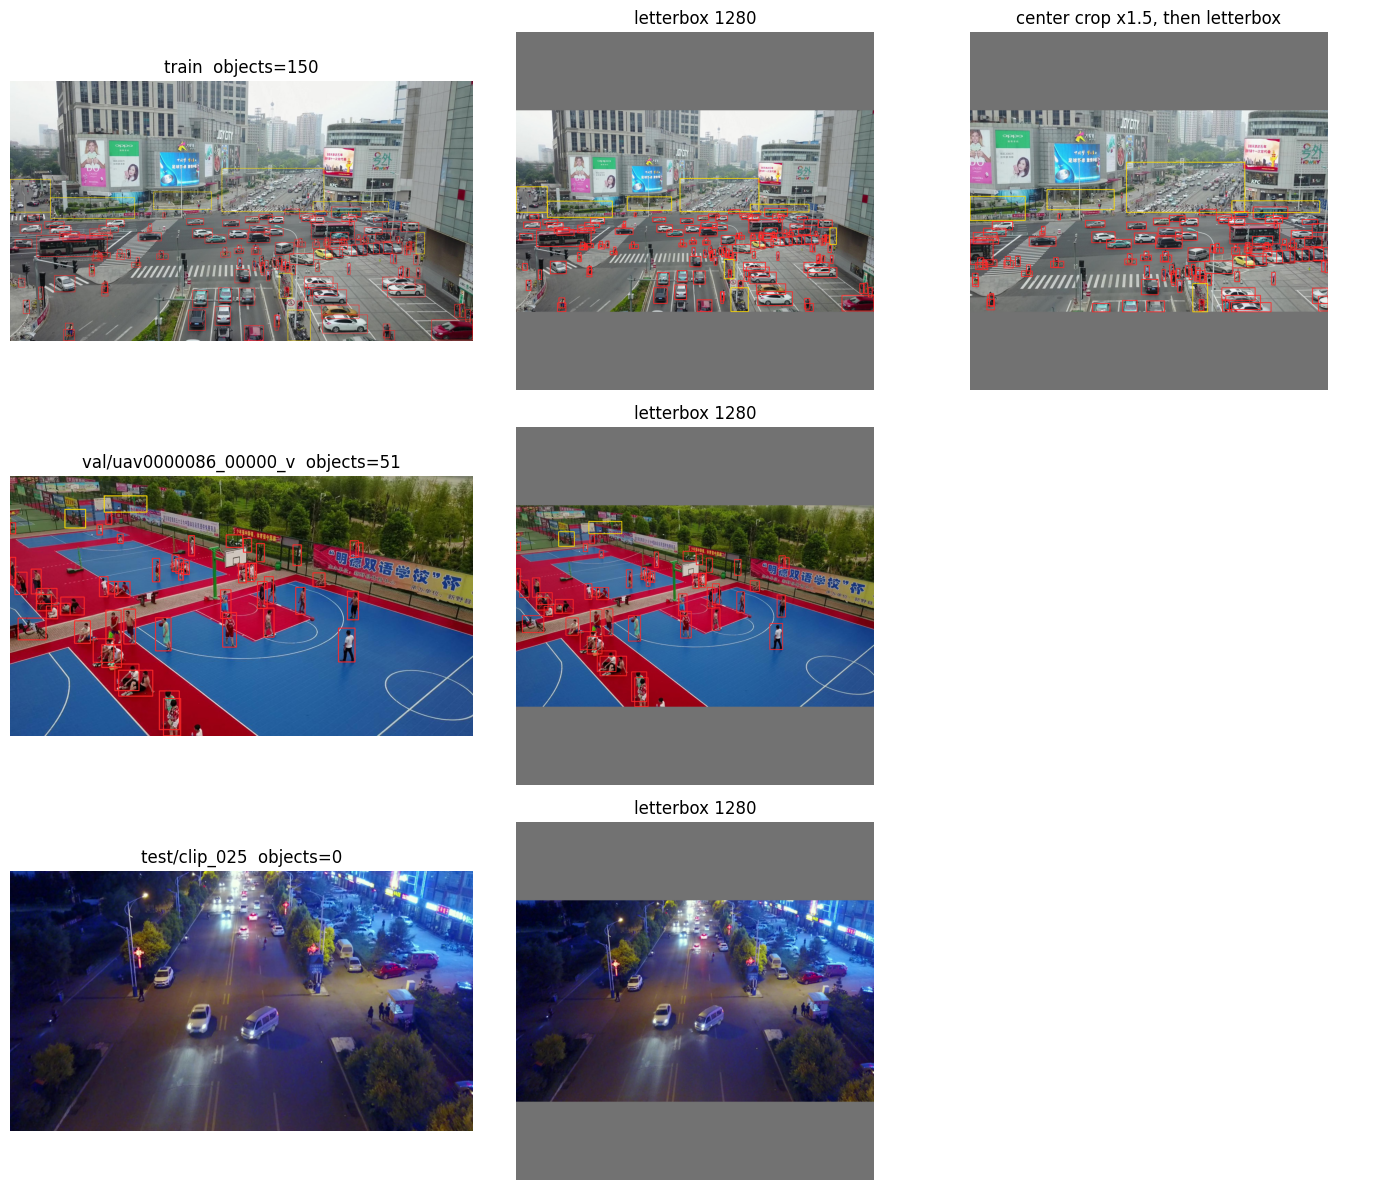

red = labeled objects, yellow = ignore. Test has no boxes.
Training scale uses a random crop. The x1.5 panel is a center crop so the factor is easy to see.
Edge boxes can be clipped, so the mean width is not exactly the factor.


In [22]:
def paint(image, boxes, color):
    view = image.copy()
    for row in boxes:
        x1, y1, x2, y2 = row[1:].astype(int)
        cv2.rectangle(view, (x1, y1), (x2, y2), color, 2)
    return view


def stack_boxes(objects, ignored):
    parts = [part for part in (objects, ignored) if len(part)]
    if not parts:
        return np.zeros((0, 5))
    return np.vstack(parts)


def by_kind(boxes):
    empty = np.zeros((0, 5))
    if len(boxes) == 0:
        return empty, empty
    ignore = boxes[:, 0] < 0
    return boxes[~ignore], boxes[ignore]


class CenterCrop:
    # The training crop is random. The check uses the center so the factor is visible.
    def randint(self, low, high):
        return low + (high - low - 1) // 2


def fit_letterbox(image, objects, ignored, factor, rng):
    fitted, fitted_boxes = scale_into_frame(
        image, stack_boxes(objects, ignored), factor, rng,
    )
    canvas, boxed = letterbox(fitted, fitted_boxes)
    boxed_objects, boxed_ignored = by_kind(boxed)
    return canvas, boxed_objects, boxed_ignored


train_paths = sorted((ROOT / "train/images/uav0000138_00000_v").glob("*.jpg"))
val_dir = sorted(p for p in (ROOT / "val/images").iterdir() if p.is_dir())[0]
val_paths = sorted(val_dir.glob("*.jpg"))
test_path = Path(test_df["image_path"].iloc[len(test_df) // 2])


def load_frame(split, sequence, stem):
    image = cv2.cvtColor(
        cv2.imread(str(ROOT / split / "images" / sequence / f"{stem}.jpg")),
        cv2.COLOR_BGR2RGB,
    )
    height, width = image.shape[:2]
    objects = yolo_to_xyxy(ROOT / split / "labels" / sequence / f"{stem}.txt", width, height)
    ignored = yolo_to_xyxy(ROOT / split / "ignore" / sequence / f"{stem}.txt", width, height)
    return image, objects, ignored


panels = [
    (*load_frame("train", "uav0000138_00000_v", train_paths[len(train_paths) // 2].stem), "train", True),
    (*load_frame("val", val_dir.name, val_paths[len(val_paths) // 2].stem), f"val/{val_dir.name}", False),
]
test_image = cv2.cvtColor(cv2.imread(str(test_path)), cv2.COLOR_BGR2RGB)
panels.append((test_image, np.zeros((0, 5)), np.zeros((0, 5)), f"test/{test_path.parent.name}", False))

fig, axes = plt.subplots(len(panels), 3, figsize=(14, 4 * len(panels)))
for row, (image, objects, ignored, title, show_scale) in zip(axes, panels):
    boxed, boxed_objects = letterbox(image, objects)
    _, boxed_ignored = letterbox(image, ignored)
    row[0].imshow(paint(paint(image, objects, (255, 40, 40)), ignored, (255, 220, 0)))
    row[0].set_title(f"{title}  objects={len(objects)}")
    row[0].axis("off")
    row[1].imshow(paint(paint(boxed, boxed_objects, (255, 40, 40)), boxed_ignored, (255, 220, 0)))
    row[1].set_title(f"letterbox {IMGSZ}")
    row[1].axis("off")
    norm = normalize(boxed)
    print(title, "letterbox normalized", float(norm.min()), float(norm.max()))
    if show_scale:
        zoom, zoom_objects, zoom_ignored = fit_letterbox(image, objects, ignored, 1.5, CenterCrop())
        row[2].imshow(paint(paint(zoom, zoom_objects, (255, 40, 40)), zoom_ignored, (255, 220, 0)))
        row[2].set_title("center crop x1.5, then letterbox")
        row[2].axis("off")
        print("mean object width at 1280, center crop")
        for factor in (0.5, 1.0, 1.5):
            _, fact_objects, _ = fit_letterbox(image, objects, ignored, factor, CenterCrop())
            if len(fact_objects) == 0:
                print(f"  factor {factor:.1f}: n=0")
                continue
            width = float((fact_objects[:, 3] - fact_objects[:, 1]).mean())
            print(f"  factor {factor:.1f}: n={len(fact_objects)} mean width {width:.1f}")
        rng = check_random_state(SEED)
        aug, aug_boxes = preprocess_train(image, stack_boxes(objects, ignored), rng)
        print(
            "preprocess_train normalized",
            float(aug.min()), float(aug.max()), "boxes", len(aug_boxes),
        )
    else:
        row[2].axis("off")
fig.tight_layout()
plt.show()
print("red = labeled objects, yellow = ignore. Test has no boxes.")
print("Training scale uses a random crop. The x1.5 panel is a center crop so the factor is easy to see.")
print("Edge boxes can be clipped, so the mean width is not exactly the factor.")


## Write results to file

In [23]:
def run_dir(section, name):
    path = RESULTS / section / name
    path.mkdir(parents=True, exist_ok=True)
    return path

def read_json(path):
    if not path.exists():
        return None
    return json.loads(path.read_text())

def write_json(path, payload):
    path.write_text(json.dumps(payload, indent=2))

def same_protocol(path, protocol):
    saved = read_json(path)
    return saved is not None and saved.get("protocol") == protocol

def per_class_ap(evaluator):
    out = {names[int(class_id)]: 0.0 for class_id in sorted(names)}
    precision = None if evaluator.eval is None else evaluator.eval.get("precision")
    if precision is None:
        return out
    for index, cat_id in enumerate(evaluator.params.catIds):
        cat_id = int(cat_id)
        if cat_id not in names:
            continue
        vals = precision[:, :, index, 0, -1]
        vals = vals[vals > -1]
        out[names[cat_id]] = float(vals.mean()) if vals.size else 0.0
    return out

def save_history(section, name, protocol, history):
    write_json(run_dir(section, name) / "history.json", {
        "model": name,
        "protocol": protocol,
        "epochs": history,
    })

## Eval

Every family is scored here, on the original frame. `VAL_COCO` is `instances_val.json` with each ignore region copied onto the eight object classes as `iscrowd=1`. The JSON file is not rewritten. Boxes predicted on the 1280 letterbox are mapped back before COCO AP, AP50, and AP_small.


In [24]:
from pycocotools.cocoeval import COCOeval


def scoring_coco(path):
    # Crowd boxes only excuse a detection of the same category. The file keeps ignore
    # under its own category, so each region is copied onto the eight object classes in memory.
    source = COCO(str(path))
    object_ids = [int(key) for key in sorted(names)]
    ignore_ids = {
        int(cat["id"])
        for cat in source.dataset["categories"]
        if cat.get("name") == "ignore"
    }
    dataset = {
        "images": source.dataset["images"],
        "categories": source.dataset["categories"],
        "annotations": list(source.dataset["annotations"]),
    }
    next_id = 1 + max((int(ann["id"]) for ann in dataset["annotations"]), default=0)
    attached = 0
    for ann in source.dataset["annotations"]:
        if int(ann["category_id"]) not in ignore_ids:
            continue
        for category_id in object_ids:
            cloned = dict(ann)
            cloned["id"] = next_id
            next_id += 1
            cloned["category_id"] = int(category_id)
            cloned["iscrowd"] = 1
            dataset["annotations"].append(cloned)
        attached += 1
    scoring = COCO()
    scoring.dataset = dataset
    scoring.createIndex()
    print(f"{Path(path).name}: {attached} ignore regions attached to {len(object_ids)} classes")
    if attached == 0:
        print("warning: no ignore category in", path)
    return scoring


def letterbox_xyxy_to_original(boxes, width, height):
    ratio, left, top = letterbox_params(int(width), int(height), IMGSZ)
    out = np.array(boxes, dtype=np.float32, copy=True).reshape(-1, 4)
    out[:, [0, 2]] -= left
    out[:, [1, 3]] -= top
    out /= float(ratio)
    out[:, [0, 2]] = np.clip(out[:, [0, 2]], 0, width)
    out[:, [1, 3]] = np.clip(out[:, [1, 3]], 0, height)
    return out


def coco_score_predictions(coco, predictions, image_ids):
    object_ids = [int(key) for key in sorted(names)]
    known = set(object_ids)
    allowed = set(int(image_id) for image_id in image_ids)
    per_class = {names[class_id]: 0.0 for class_id in object_ids}
    empty = {
        "mAP": 0.0,
        "AP50": 0.0,
        "AP_small": 0.0,
        "AP_per_class": per_class,
        "predictions": [],
    }
    cleaned = []
    for row in predictions:
        category_id = int(row["category_id"])
        image_id = int(row["image_id"])
        width, height = float(row["bbox"][2]), float(row["bbox"][3])
        score = float(row["score"])
        if category_id not in known or image_id not in allowed or width <= 0 or height <= 0 or score != score:
            continue
        cleaned.append({
            "image_id": image_id,
            "category_id": category_id,
            "bbox": [float(value) for value in row["bbox"]],
            "score": score,
        })
    if not cleaned:
        print("no predictions; AP is 0")
        return empty
    detected = coco.loadRes(cleaned)
    evaluator = COCOeval(coco, detected, "bbox")
    evaluator.params.catIds = object_ids
    evaluator.params.imgIds = sorted(allowed)
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    def clean(value):
        value = float(value)
        if value != value or value < 0:
            return 0.0
        return value

    return {
        "mAP": clean(evaluator.stats[0]),
        "AP50": clean(evaluator.stats[1]),
        "AP_small": clean(evaluator.stats[3]),
        "AP_per_class": per_class_ap(evaluator),
        "predictions": cleaned,
    }


def eval_frame_path(dataset, index):
    if hasattr(dataset, "paths"):
        return dataset.paths[index]
    return dataset.base.paths[dataset.indexes[index]]


def coco_score(model, dataset):
    model.eval()
    index = {}
    sizes = {}
    for image in VAL_COCO.dataset["images"]:
        image_id = int(image["id"])
        index[(image["sequence"], str(image["frame"]))] = image_id
        sizes[image_id] = (int(image["width"]), int(image["height"]))
    detections = []
    image_ids = []
    for item in range(len(dataset)):
        path = Path(eval_frame_path(dataset, item))
        key = (path.parent.name, str(path.stem))
        if key not in index:
            raise KeyError(f"{path} is not in the validation COCO file")
        image_id = index[key]
        image_ids.append(image_id)
        image, _ = dataset[item]
        with torch.no_grad():
            pred = model([image.to(device)])[0]
        boxes = pred["boxes"].detach().cpu().numpy()
        labels = pred["labels"].detach().cpu().numpy()
        scores = pred["scores"].detach().cpu().numpy()
        width, height = sizes[image_id]
        if len(boxes):
            boxes = letterbox_xyxy_to_original(boxes, width, height)
        for box, label, score in zip(boxes, labels, scores):
            category_id = int(label) - 1
            if category_id not in names:
                continue
            x1, y1, x2, y2 = (float(value) for value in box)
            if x2 <= x1 or y2 <= y1 or float(score) != float(score):
                continue
            detections.append({
                "image_id": image_id,
                "category_id": category_id,
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "score": float(score),
            })
    return coco_score_predictions(VAL_COCO, detections, image_ids)


val_json = ROOT / "annotations" / "instances_val.json"
if not val_json.is_file():
    raise FileNotFoundError(
        "instances_val.json is missing. Run the COCO cell above. This section does not rewrite it."
    )
VAL_COCO = scoring_coco(val_json)

def milliseconds_per_frame(model, n=100):
    model.eval()
    frames = [val_set[i][0].to(device) for i in range(n)]
    for image in frames[:10]:
        with torch.no_grad():
            model([image])
    torch.cuda.synchronize()
    start = time.perf_counter()
    for image in frames:
        with torch.no_grad():
            model([image])
    torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - start) / n

loading annotations into memory...
Done (t=0.35s)
creating index...
index created!
creating index...
index created!
instances_val.json: 3995 ignore regions attached to 8 classes


## One-stage detectors

We compare four COCO-pretrained one-stage detectors under one protocol and keep two of them: the better anchor-based model and the better anchor-free model. RetinaNet-ResNet50 and YOLOv5s are the anchor-based pair. FCOS-ResNet50 and YOLOX-s are the anchor-free pair.

The number that chooses the pair is COCO AP on the 7 validation clips. Every model is trained once, on all 56 training clips, and scored on that same validation set. The validation clips are other videos, so a frame from a training clip never enters the score.

Every fit uses the letterbox, padding, scaler, flip, and scale already defined above. Those functions are called as they are. Nothing here writes a new image or a new annotation file. The scaler was fit on the two endpoints `[0, 255]`, not on pixels from the images, so it does not depend on which clips are scored. Validation frames go through `preprocess_val` only.

This section is the comparison. This extended comparison uses 4000 optimizer steps and a stable 0.5 learning-rate multiplier for every detector. The earlier tuning block remains in the notebook as commented code. Anchor scales stay at the COCO priors: the 1280 size table is the measurement those later runs should use.



### Setup

A step is one optimizer update. All four models use batch 2 and 400 steps, so each model sees 800 images. The same count is what makes the table a comparison of heads rather than of batch sizes.

The library learning rates were published for a larger batch: 0.02 at batch 16 for the torchvision models, and 0.01 at a nominal batch of 64 for YOLOv5 and YOLOX. We scale those rates by `batch / reference batch`. The new 8-class classification layer starts from random weights, so its learning rate is ten times the backbone rate. Warmup is the first 20 of the 400 steps. Leaving a third of the budget in warmup would spend the run before that new layer had taken a real step.

A finished run is written under `results/one_stage`. A second start skips a model only when its validation predictions were written by this same protocol, so a Colab disconnect does not throw away a fit that completed and an older budget is not reused. A weight file is kept only when it is at least the size of the published release. Data loading stays on the main process. OpenCV inside a notebook worker is a common hang, so `num_workers` is 0.



In [25]:
import gc
import json
import random
import shutil
import subprocess
import sys
import time
import traceback
import urllib.request

import cv2
import torch
import yaml

# OpenCV's own thread pool deadlocks with the notebook kernel even when the loader has no workers.
cv2.setNumThreads(0)
torch.backends.cudnn.benchmark = True

if not torch.cuda.is_available():
    raise RuntimeError(
        "Switch the Colab runtime to a GPU and run the notebook from the top. "
        "This section does not train on CPU."
    )

for _name in (
    "ROOT", "RESULTS", "names", "IMGSZ", "SEED", "train_frame_sizes", "val_frame_sizes",
    "preprocess_train", "preprocess_val", "letterbox_params", "yolo_to_xyxy", "check_random_state",
):
    if _name not in globals():
        raise RuntimeError(f"{_name} is missing. Run the cells above this section before training.")

if sorted(int(key) for key in names) != list(range(len(names))):
    raise RuntimeError(f"These heads index class ids 0..n-1. data.yaml has {sorted(names)}.")

ONE_STAGE_BATCH = 2
ONE_STAGE_STEPS = 4000
ONE_STAGE_WARMUP = 200
ONE_STAGE_HEAD_LR = 10.0
ONE_STAGE_SCORE = 0.01
ONE_STAGE_MAX_DET = 500
ONE_STAGE_NMS = 0.65
ONE_STAGE_DIR = RESULTS / "one_stage"
ONE_STAGE_DIR.mkdir(parents=True, exist_ok=True)
ONE_STAGE_WEIGHTS_DIR = ONE_STAGE_DIR / "weights"
ONE_STAGE_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

# Extended-budget comparison settings. The lower LR is the stable value observed in the prior YOLOX run.
ONE_STAGE_VARIANT = "baseline"
ONE_STAGE_LR_MULTIPLIER = 0.5
ONE_STAGE_LOSS_MULTIPLIER = 1.0

print(
    "one-stage",
    "batch", ONE_STAGE_BATCH,
    "steps", ONE_STAGE_STEPS,
    "images per fit", ONE_STAGE_BATCH * ONE_STAGE_STEPS,
    "input", IMGSZ,
    "classes", len(names),
)


def one_stage_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def one_stage_is_oom(exc):
    if type(exc).__name__ == "OutOfMemoryError":
        return True
    return "out of memory" in str(exc).lower()


def one_stage_dump(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(payload))
    temporary.replace(path)


def one_stage_variant_dir(name, variant=None):
    variant = variant or ONE_STAGE_VARIANT
    return ONE_STAGE_DIR / name if variant == "baseline" else ONE_STAGE_DIR / f"{name}_{variant}"


def one_stage_checkpoint_path(name, variant=None):
    variant = variant or ONE_STAGE_VARIANT
    return ONE_STAGE_WEIGHTS_DIR / f"{name}_{variant}.pt"


def one_stage_save_checkpoint(path, model, metadata):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    state_dict = {
        key: value.detach().cpu()
        for key, value in model.state_dict().items()
    }
    checkpoint = {"state_dict": state_dict, "metadata": metadata}
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(path)
    print(f"saved checkpoint {path} ({path.stat().st_size / 1024**2:.1f} MiB)", flush=True)


def one_stage_checkpoint_metadata(name, family, batch, steps, seed, extra=None):
    metadata = {
        "model_name": name,
        "variant": ONE_STAGE_VARIANT,
        "family": family,
        "num_classes": len(names),
        "class_names": dict(names),
        "imgsz": int(IMGSZ),
        "batch": int(batch),
        "steps": int(steps),
        "seed": int(seed),
        "lr_multiplier": float(ONE_STAGE_LR_MULTIPLIER),
        "loss_multiplier": float(ONE_STAGE_LOSS_MULTIPLIER),
        "protocol": one_stage_protocol_stamp(),
    }
    if extra:
        metadata.update(extra)
    return metadata


def one_stage_clone(url, dest, branch):
    dest = Path(dest)
    if (dest / ".git").is_dir():
        return dest
    if dest.exists():
        shutil.rmtree(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    subprocess.check_call(["git", "clone", "--depth", "1", "--branch", branch, url, str(dest)])
    return dest


def one_stage_download(url, dest, min_bytes):
    dest = Path(dest)
    if dest.is_file() and dest.stat().st_size >= int(min_bytes):
        return dest
    if dest.exists():
        dest.unlink()
    dest.parent.mkdir(parents=True, exist_ok=True)
    print("downloading", url, flush=True)
    urllib.request.urlretrieve(url, dest)
    if dest.stat().st_size < int(min_bytes):
        size = dest.stat().st_size
        dest.unlink()
        raise RuntimeError(f"{url} saved {size} bytes, expected at least {int(min_bytes)}")
    return dest


def one_stage_push(path):
    repo = str(Path(path).resolve())
    if repo not in sys.path:
        sys.path.insert(0, repo)
    return repo


def one_stage_drop_modules(prefixes, root):
    root = str(root)
    for key in list(sys.modules):
        if key in prefixes or any(key.startswith(prefix + ".") for prefix in prefixes):
            module = sys.modules.get(key)
            file = getattr(module, "__file__", None) or ""
            if not file or root in str(file):
                del sys.modules[key]


def one_stage_load_torch(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "psutil", "tqdm", "loguru", "tabulate", "thop",
])


one-stage batch 2 steps 4000 images per fit 8000 input 1280 classes 8


0

### Train and validation clips

Training uses all 56 clips. The score uses the 7 validation clips shipped with the data. A frame-level split would put neighbouring frames of one clip on both sides of the score, so the official clip lists stay whole. No training clip is also a validation clip.

The validation COCO file stores ignore regions as `iscrowd=1` under a category named `ignore`. pycocotools only suppresses a detection when the crowd box has the same category, so a person box inside an ignore region would still count as a false positive. The Eval section copies each ignore region onto all eight classes in memory and keeps that object as `VAL_COCO`. This section scores with that same object. The JSON file is not rewritten.



In [26]:
from pycocotools.coco import COCO


def one_stage_scoring_coco(path):
    return scoring_coco(path)


def one_stage_image_index(coco):
    index = {}
    for image in coco.dataset["images"]:
        index[(image["sequence"], str(image["frame"]))] = int(image["id"])
    return index


def one_stage_records(sizes, split, id_index):
    records = []
    for row in sizes.itertuples(index=False):
        path = Path(row.image_path)
        key = (row.sequence, path.stem)
        if key not in id_index:
            key = (row.sequence, str(row.frame))
        if key not in id_index:
            raise KeyError(f"{split} frame {row.sequence}/{path.stem} is not in the COCO json")
        records.append({
            "split": split,
            "sequence": row.sequence,
            "frame": path.stem,
            "path": row.image_path,
            "width": int(row.img_w),
            "height": int(row.img_h),
            "image_id": id_index[key],
        })
    return records


train_json = ROOT / "annotations" / "instances_train.json"
val_json = ROOT / "annotations" / "instances_val.json"
if not train_json.is_file() or not val_json.is_file():
    raise FileNotFoundError(
        "instances_train.json and instances_val.json are missing. Run the COCO cell above. This section does not rewrite them."
    )

train_source = COCO(str(train_json))
ONE_STAGE_TRAIN = one_stage_records(train_frame_sizes, "train", one_stage_image_index(train_source))
del train_source
if "VAL_COCO" not in globals():
    raise RuntimeError("VAL_COCO is missing. Run the Eval cell before this section.")
ONE_STAGE_VAL_COCO = VAL_COCO
ONE_STAGE_VAL = one_stage_records(val_frame_sizes, "val", one_stage_image_index(ONE_STAGE_VAL_COCO))

train_sequences = sorted({record["sequence"] for record in ONE_STAGE_TRAIN})
val_sequences = sorted({record["sequence"] for record in ONE_STAGE_VAL})
if len(train_sequences) != 56:
    raise RuntimeError(f"Expected 56 training clips, found {len(train_sequences)}.")
if len(val_sequences) != 7:
    raise RuntimeError(f"Expected 7 validation clips, found {len(val_sequences)}.")
shared_sequences = set(train_sequences) & set(val_sequences)
if shared_sequences:
    raise RuntimeError(f"Train and val share clips: {sorted(shared_sequences)}")

train_ids = [record["image_id"] for record in ONE_STAGE_TRAIN]
val_ids = [record["image_id"] for record in ONE_STAGE_VAL]
if len(train_ids) != len(set(train_ids)) or len(val_ids) != len(set(val_ids)):
    raise RuntimeError("COCO image ids are not unique inside a split")
print("train clips", len(train_sequences))
print(", ".join(train_sequences))
print("val clips", len(val_sequences))
print(", ".join(val_sequences))
print("frames", "train", len(ONE_STAGE_TRAIN), "val", len(ONE_STAGE_VAL))



loading annotations into memory...
Done (t=3.85s)
creating index...
index created!
train clips 56
uav0000013_00000_v, uav0000013_01073_v, uav0000013_01392_v, uav0000020_00406_v, uav0000071_03240_v, uav0000072_04488_v, uav0000072_05448_v, uav0000072_06432_v, uav0000076_00720_v, uav0000079_00480_v, uav0000084_00000_v, uav0000099_02109_v, uav0000124_00944_v, uav0000126_00001_v, uav0000138_00000_v, uav0000140_01590_v, uav0000143_02250_v, uav0000145_00000_v, uav0000150_02310_v, uav0000218_00001_v, uav0000222_03150_v, uav0000239_03720_v, uav0000239_12336_v, uav0000243_00001_v, uav0000244_01440_v, uav0000248_00001_v, uav0000263_03289_v, uav0000264_02760_v, uav0000266_03598_v, uav0000266_04830_v, uav0000270_00001_v, uav0000273_00001_v, uav0000278_00001_v, uav0000279_00001_v, uav0000281_00460_v, uav0000288_00001_v, uav0000289_00001_v, uav0000289_06922_v, uav0000295_02300_v, uav0000300_00000_v, uav0000307_00000_v, uav0000308_00000_v, uav0000308_01380_v, uav0000309_00000_v, uav0000315_00000_v, ua

### Loader and score

Training frames go through `preprocess_train`: flip with probability 0.5, a scale in `[0.5, 1.5]` fitted back to the original frame, then letterbox to 1280 and the scaler. Validation frames go through `preprocess_val`, which is letterbox and the scaler only. Ignore boxes are not targets. Empty frames stay in the loader so the image list matches the COCO file.

Torchvision and YOLOv5 read that canvas as RGB in `[0, 1]`. Torchvision then applies its own ImageNet normalization inside the model. YOLOX reads the same pixels as BGR in `[0, 255]`, which is the range of its COCO checkpoint. None of the three letterboxes again, and YOLOX mosaic stays off. A second geometric transform would move the boxes away from the labels.

Predictions are mapped back with `letterbox_params` into the original frame and scored with pycocotools. The average uses the eight classes in `names`. The printed AP is COCO AP at IoU 0.50:0.95 with at most 100 detections per image. Each image keeps its top 500 boxes before that, which is the submission cap, and the evaluator then keeps the COCO top 100. All four models suppress overlapping boxes of the same class at IoU 0.65. AP50 and AP_small come from the same call. The validation milliseconds per image include letterbox, the forward pass, and NMS.



In [27]:
from torch.utils.data import DataLoader


class OneStageCanvas(torch.utils.data.Dataset):
    def __init__(self, records, augment, seed):
        self.records = list(records)
        self.augment = bool(augment)
        self.seed = int(seed)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        image = one_stage_read_image(record)
        label_path = ROOT / record["split"] / "labels" / record["sequence"] / f"{record['frame']}.txt"
        boxes = yolo_to_xyxy(label_path, record["width"], record["height"])
        if len(boxes):
            boxes = boxes[boxes[:, 0] >= 0]
        else:
            boxes = np.zeros((0, 5), dtype=np.float64)
        rng = check_random_state(self.seed + index)
        if self.augment:
            canvas, boxes = preprocess_train(image, boxes, rng)
        else:
            canvas, boxes = preprocess_val(image, boxes)
        return canvas, np.asarray(boxes), record


def one_stage_read_image(record):
    bgr = cv2.imread(record["path"])
    if bgr is None:
        raise FileNotFoundError(record["path"])
    image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    if width != record["width"] or height != record["height"]:
        raise RuntimeError(
            f"Decoded shape {(width, height)} does not match the COCO size "
            f"{(record['width'], record['height'])} for {record['path']}"
        )
    return image


def one_stage_keep_boxes(boxes):
    boxes = np.asarray(boxes, dtype=np.float32)
    if boxes.size == 0:
        return np.zeros((0, 5), dtype=np.float32)
    boxes = boxes.reshape(-1, boxes.shape[-1])
    if boxes.shape[1] < 5:
        return np.zeros((0, 5), dtype=np.float32)
    kept = boxes[:, :5].copy()
    kept[:, [1, 3]] = np.clip(kept[:, [1, 3]], 0, IMGSZ)
    kept[:, [2, 4]] = np.clip(kept[:, [2, 4]], 0, IMGSZ)
    finite = np.isfinite(kept).all(axis=1)
    positive = (kept[:, 3] > kept[:, 1]) & (kept[:, 4] > kept[:, 2])
    classes = np.rint(kept[:, 0]).astype(np.int64)
    known = np.array([int(class_id) in names for class_id in classes], dtype=bool)
    kept = kept[finite & positive & known]
    kept[:, 0] = np.rint(kept[:, 0])
    return kept


def one_stage_to_original(boxes, width, height):
    return letterbox_xyxy_to_original(boxes, width, height)


def one_stage_coco_rows(boxes, scores, labels, image_id):
    rows = []
    for box, score, label in zip(boxes, scores, labels):
        x1, y1, x2, y2 = (float(value) for value in box)
        box_w = x2 - x1
        box_h = y2 - y1
        score = float(score)
        label = int(label)
        if box_w <= 0 or box_h <= 0 or score != score or label not in names:
            continue
        rows.append({
            "image_id": int(image_id),
            "category_id": label,
            "bbox": [x1, y1, box_w, box_h],
            "score": score,
        })
    if len(rows) > ONE_STAGE_MAX_DET:
        rows.sort(key=lambda row: row["score"], reverse=True)
        del rows[ONE_STAGE_MAX_DET:]
    return rows


def one_stage_loader(records, augment, seed, batch):
    if len(records) < 1:
        raise RuntimeError("A fit was given no frames")
    generator = torch.Generator()
    generator.manual_seed(int(seed))
    return DataLoader(
        OneStageCanvas(records, augment, seed),
        batch_size=int(batch),
        shuffle=True,
        num_workers=0,
        collate_fn=lambda batch_rows: batch_rows,
        generator=generator,
        pin_memory=False,
    )


def one_stage_batches(loader):
    iterator = iter(loader)
    while True:
        try:
            yield next(iterator)
        except StopIteration:
            iterator = iter(loader)
            yield next(iterator)


def one_stage_sgd(named_params, base_lr, head_lr, weight_decay, momentum, nesterov, is_head):
    grouped = {(False, False): [], (False, True): [], (True, False): [], (True, True): []}
    seen = set()
    for name, param in named_params:
        if not param.requires_grad or id(param) in seen:
            continue
        seen.add(id(param))
        no_decay = param.ndim <= 1 or name.endswith(".bias")
        grouped[(bool(is_head(name)), no_decay)].append(param)
    specs = []
    for (head, no_decay), params in grouped.items():
        if not params:
            continue
        lr = head_lr if head else base_lr
        specs.append({
            "params": params,
            "lr": lr,
            "target_lr": lr,
            "weight_decay": 0.0 if no_decay else weight_decay,
        })
    if not specs:
        raise RuntimeError("The model has no trainable parameters")
    return torch.optim.SGD(specs, lr=base_lr, momentum=momentum, nesterov=nesterov)


def one_stage_freeze_bn(model):
    # Batch 2 with a small fine-tuning budget should not replace COCO running statistics. Keep them.
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
            for param in module.parameters():
                param.requires_grad = False


def one_stage_protocol_stamp():
    return (
        f"split=official variant={ONE_STAGE_VARIANT} imgsz={int(IMGSZ)} "
        f"batch={int(ONE_STAGE_BATCH)} steps={int(ONE_STAGE_STEPS)} "
        f"lr_mult={ONE_STAGE_LR_MULTIPLIER:.3f} loss_mult={ONE_STAGE_LOSS_MULTIPLIER:.3f} "
        f"score={ONE_STAGE_SCORE:.2f} nms={ONE_STAGE_NMS:.2f} "
        f"max_det={int(ONE_STAGE_MAX_DET)} warmup={int(ONE_STAGE_WARMUP)}"
    )


def one_stage_warmup(optimizer, step):
    fraction = 1.0 if step >= ONE_STAGE_WARMUP else float(step + 1) / float(ONE_STAGE_WARMUP)
    for group in optimizer.param_groups:
        group["lr"] = group["target_lr"] * fraction


def one_stage_amp():
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=True)

        def context():
            return torch.amp.autocast("cuda", enabled=True)

        return scaler, context
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=True)

        def context():
            return torch.cuda.amp.autocast(enabled=True)

        return scaler, context


def one_stage_score(coco, predictions, image_ids):
    row = coco_score_predictions(coco, predictions, image_ids)
    return {
        "ap": row["mAP"],
        "ap50": row["AP50"],
        "ap_small": row["AP_small"],
        "per_class": row["AP_per_class"],
    }


def one_stage_predict(records, batch, infer_batch):
    if len(records) == 0:
        return [], 0.0
    started = time.perf_counter()

    def run(active_batch):
        predictions = []
        done = 0
        for start in range(0, len(records), active_batch):
            chunk = records[start:start + active_batch]
            canvases = []
            for record in chunk:
                canvas, _ = preprocess_val(one_stage_read_image(record), np.zeros((0, 5), dtype=np.float64))
                canvases.append(canvas)
            outputs = infer_batch(canvases)
            if len(outputs) != len(chunk):
                raise RuntimeError("Inference returned a different number of images than the batch")
            for record, (boxes, scores, labels) in zip(chunk, outputs):
                boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
                scores = np.asarray(scores, dtype=np.float32).reshape(-1)
                labels = np.asarray(labels).reshape(-1)
                if len(boxes):
                    boxes = one_stage_to_original(boxes, record["width"], record["height"])
                predictions.extend(one_stage_coco_rows(boxes, scores, labels, record["image_id"]))
            done += len(chunk)
            if done == len(records) or done % 200 == 0:
                print(f"eval {done}/{len(records)}", flush=True)
        return predictions

    try:
        predictions = run(int(batch))
    except Exception as exc:
        if not one_stage_is_oom(exc) or int(batch) == 1:
            raise
        print("CUDA out of memory during eval; scoring one image at a time", flush=True)
        gc.collect()
        torch.cuda.empty_cache()
        predictions = run(1)
    elapsed_ms = (time.perf_counter() - started) * 1000.0 / len(records)
    return predictions, elapsed_ms


def one_stage_run_path(name):
    return one_stage_variant_dir(name) / "val.json"


def one_stage_load_run(name):
    path = one_stage_run_path(name)
    if not path.is_file():
        return None
    payload = json.loads(path.read_text())
    metrics = payload.get("metrics") or {}
    if payload.get("protocol") != one_stage_protocol_stamp():
        print(f"{name} was saved under a different protocol, running it again", flush=True)
        return None
    if not metrics.get("ok") or "predictions" not in payload:
        return None
    checkpoint = one_stage_checkpoint_path(name)
    if not checkpoint.is_file():
        print(f"{name} has metrics but no checkpoint; running it again", flush=True)
        return None
    return metrics


def one_stage_save_run(name, metrics, predictions):
    one_stage_dump(
        one_stage_run_path(name),
        {"metrics": metrics, "predictions": predictions, "protocol": one_stage_protocol_stamp()},
    )


def one_stage_store_summary(summary):
    path = ONE_STAGE_DIR / "results.json"
    rows = json.loads(path.read_text()) if path.is_file() else []
    rows = [
        row for row in rows
        if not (row.get("name") == summary["name"] and row.get("variant", "baseline") == summary.get("variant", "baseline"))
    ]
    rows.append(summary)
    one_stage_dump(path, rows)


def one_stage_failed(name, family, error):
    summary = {
        "name": name,
        "variant": ONE_STAGE_VARIANT,
        "family": family,
        "ok": False,
        "error": error,
        "val_ap": None,
        "val_ap50": None,
        "val_ap_small": None,
        "val_per_class": {},
        "val_ms_per_image": None,
        "images_seen": None,
        "batch": None,
        "steps": None,
        "last_loss": None,
    }
    one_stage_store_summary(summary)
    return summary


def one_stage_guard(name, family, runner):
    # An import or clone failure must not stop the later models or the comparison cell.
    try:
        return runner()
    except Exception:
        error = traceback.format_exc()
        print(error)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return one_stage_failed(name, family, error)


def one_stage_call(train_predict, train_records, eval_records, seed):
    attempts = (
        (ONE_STAGE_BATCH, ONE_STAGE_STEPS),
        (1, ONE_STAGE_STEPS * ONE_STAGE_BATCH),
    )
    for index, (batch, steps) in enumerate(attempts):
        try:
            return train_predict(train_records, eval_records, batch, steps, seed)
        except Exception as exc:
            if index == len(attempts) - 1 or not one_stage_is_oom(exc):
                raise
            print(
                f"CUDA out of memory; retrying at batch 1 for the same "
                f"{ONE_STAGE_BATCH * ONE_STAGE_STEPS} images",
                flush=True,
            )
            gc.collect()
            torch.cuda.empty_cache()


def one_stage_plain_metrics(metrics):
    plain = {}
    for key, value in metrics.items():
        if isinstance(value, dict):
            plain[key] = {str(name): float(item) for name, item in value.items()}
        elif isinstance(value, bool) or value is None or isinstance(value, str):
            plain[key] = value
        elif isinstance(value, int):
            plain[key] = int(value)
        else:
            plain[key] = float(value)
    return plain


def one_stage_protocol(name, family, train_predict):
    summary = {
        "name": name,
        "variant": ONE_STAGE_VARIANT,
        "family": family,
        "ok": False,
        "error": "",
        "val_ap": None,
        "val_ap50": None,
        "val_ap_small": None,
        "val_per_class": {},
        "val_ms_per_image": None,
        "images_seen": None,
        "batch": None,
        "steps": None,
        "last_loss": None,
    }
    try:
        saved = one_stage_load_run(name)
        if saved is not None:
            val = saved
            val_ms = saved.get("ms_per_image")
            print(f"{name} val already done, AP {val['ap']:.4f}", flush=True)
        else:
            train_clips = len({record["sequence"] for record in ONE_STAGE_TRAIN})
            print(
                f"{name} train clips {train_clips} frames {len(ONE_STAGE_TRAIN)} "
                f"val clips {len(val_sequences)} frames {len(ONE_STAGE_VAL)}",
                flush=True,
            )
            predictions, info = one_stage_call(train_predict, ONE_STAGE_TRAIN, ONE_STAGE_VAL, SEED)
            val_metrics = one_stage_score(
                ONE_STAGE_VAL_COCO, predictions, [record["image_id"] for record in ONE_STAGE_VAL],
            )
            val = one_stage_plain_metrics({**info, **val_metrics, "ok": True})
            one_stage_save_run(name, val, predictions)
            val_ms = info.get("ms_per_image")
            print(
                f"{name} val AP {val_metrics['ap']:.4f} AP50 {val_metrics['ap50']:.4f} "
                f"AP_small {val_metrics['ap_small']:.4f}",
                flush=True,
            )
        summary.update({
            "ok": True,
            "error": "",
            "val_ap": val["ap"],
            "val_ap50": val["ap50"],
            "val_ap_small": val["ap_small"],
            "val_per_class": val["per_class"],
            "val_ms_per_image": None if val_ms is None else float(val_ms),
            "images_seen": val.get("images_seen"),
            "batch": val.get("batch"),
            "steps": val.get("steps"),
            "last_loss": val.get("last_loss"),
        })
    except Exception:
        summary["error"] = traceback.format_exc()
        summary["ok"] = False
        print(summary["error"])
    finally:
        gc.collect()
        torch.cuda.empty_cache()
    one_stage_store_summary(summary)
    return summary


def one_stage_check_geometry():
    image = np.zeros((360, 640, 3), dtype=np.uint8)
    boxes = np.array([[2, 10, 20, 110, 80]], dtype=np.float64)
    _canvas, moved = preprocess_val(image, boxes)
    back = one_stage_to_original(moved[:, 1:5], 640, 360)
    error = float(np.max(np.abs(back[0] - boxes[0, 1:5])))
    if error > 1e-2:
        raise RuntimeError(f"Letterbox round-trip failed by {error:.4f} px")
    print("letterbox round-trip max error", round(error, 5))


one_stage_check_geometry()


letterbox round-trip max error 0.0


### RetinaNet

RetinaNet-ResNet50-FPN starts from the torchvision COCO weights. We replace the classification head for the eight classes and leave the regression head and the backbone. The new classification head is the parameter group with the higher learning rate. Focal loss stays at the library default; changing its gamma is one of the later experiments, not part of this comparison.



In [28]:
def one_stage_run_retinanet():
    from torchvision.models.detection import retinanet_resnet50_fpn

    weights_enum = None
    try:
        from torchvision.models.detection import RetinaNet_ResNet50_FPN_Weights
        weights_enum = RetinaNet_ResNet50_FPN_Weights
    except ImportError:
        pass

    def build():
        try:
            model = retinanet_resnet50_fpn(weights="DEFAULT")
        except TypeError:
            if weights_enum is None:
                raise
            model = retinanet_resnet50_fpn(weights=weights_enum.DEFAULT)
        one_stage_replace_cls_head(model, len(names))
        one_stage_prepare_tv(model)
        return model

    def infer_factory(model):
        device = torch.device("cuda")

        def infer(canvases):
            tensors = [
                torch.from_numpy(np.ascontiguousarray(canvas)).permute(2, 0, 1).to(device).float()
                for canvas in canvases
            ]
            model.eval()
            with torch.no_grad():
                outputs = model(tensors)
            results = []
            for output in outputs:
                results.append((
                    output["boxes"].detach().cpu().numpy(),
                    output["scores"].detach().cpu().numpy(),
                    output["labels"].detach().cpu().numpy(),
                ))
            return results

        return infer

    return one_stage_run_tv("retinanet", "anchor-based", build, infer_factory)


def one_stage_replace_cls_head(model, num_classes):
    import inspect

    current = model.head.classification_head
    head_cls = type(current)
    kwargs = {
        "in_channels": model.backbone.out_channels,
        "num_classes": num_classes,
    }
    # RetinaNet's head takes num_anchors. FCOS's head does not.
    num_anchors = getattr(current, "num_anchors", None)
    if num_anchors is not None:
        kwargs["num_anchors"] = num_anchors
    accepted = inspect.signature(head_cls.__init__).parameters
    model.head.classification_head = head_cls(**{key: value for key, value in kwargs.items() if key in accepted})


def one_stage_prepare_tv(model):
    model.transform.min_size = (IMGSZ,)
    model.transform.max_size = IMGSZ
    if hasattr(model.transform, "fixed_size"):
        model.transform.fixed_size = (IMGSZ, IMGSZ)
    model.score_thresh = ONE_STAGE_SCORE
    model.nms_thresh = ONE_STAGE_NMS
    model.detections_per_img = ONE_STAGE_MAX_DET


def one_stage_tv_targets(rows, device):
    images = []
    targets = []
    for canvas, boxes, _record in rows:
        kept = one_stage_keep_boxes(boxes)
        images.append(torch.from_numpy(np.ascontiguousarray(canvas)).permute(2, 0, 1).to(device).float())
        targets.append({
            "boxes": torch.as_tensor(kept[:, 1:5], dtype=torch.float32, device=device).reshape(-1, 4),
            "labels": torch.as_tensor(kept[:, 0], dtype=torch.int64, device=device).reshape(-1),
        })
    return images, targets


def one_stage_run_tv(name, family, build, infer_factory):
    def train_predict(train_records, eval_records, batch, steps, seed):
        device = torch.device("cuda")
        one_stage_seed(seed)
        model = build()
        model.to(device)
        base_lr = 0.02 * (float(batch) / 16.0) * ONE_STAGE_LR_MULTIPLIER
        optimizer = one_stage_sgd(
            model.named_parameters(),
            base_lr,
            base_lr * ONE_STAGE_HEAD_LR,
            5e-4,
            0.9,
            False,
            lambda param_name: "classification_head" in param_name,
        )
        print(
            f"{name} batch {batch} steps {steps} images {batch * steps} "
            f"lr {base_lr:.6f} head lr {base_lr * ONE_STAGE_HEAD_LR:.6f}",
            flush=True,
        )
        scaler, autocast = one_stage_amp()
        loader = one_stage_loader(train_records, True, seed, batch)
        stream = one_stage_batches(loader)
        model.train()
        last_loss = None
        started = time.perf_counter()
        try:
            for step in range(int(steps)):
                rows = next(stream)
                images, targets = one_stage_tv_targets(rows, device)
                one_stage_warmup(optimizer, step)
                optimizer.zero_grad(set_to_none=True)
                with autocast():
                    loss_dict = model(images, targets)
                    loss = sum(loss_dict.values())
                if not torch.isfinite(loss):
                    detail = {key: float(value.detach().cpu()) for key, value in loss_dict.items()}
                    raise RuntimeError(f"non-finite {name} loss at step {step}: {detail}")
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                last_loss = float(loss.detach().cpu())
                if step == 0 or (step + 1) % 50 == 0 or step + 1 == int(steps):
                    print(f"step {step + 1}/{int(steps)} loss {last_loss:.4f}", flush=True)
            predictions, ms_per_image = one_stage_predict(eval_records, batch, infer_factory(model))
            one_stage_save_checkpoint(
                one_stage_checkpoint_path(name),
                model,
                one_stage_checkpoint_metadata(name, family, batch, steps, seed),
            )
            return predictions, {
                "last_loss": last_loss,
                "batch": int(batch),
                "steps": int(steps),
                "images_seen": int(batch) * int(steps),
                "ms_per_image": ms_per_image,
                "seconds": time.perf_counter() - started,
            }
        finally:
            del model, optimizer
            gc.collect()
            torch.cuda.empty_cache()

    return one_stage_protocol(name, family, train_predict)


# Run and persist the RetinaNet baseline under the extended 4000-step protocol.
one_stage_retinanet = one_stage_guard("retinanet", "anchor-based", one_stage_run_retinanet)
print("retinanet val AP", one_stage_retinanet.get("val_ap"))


retinanet train clips 56 frames 24201 val clips 7 frames 2846
Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 171MB/s]


retinanet batch 2 steps 4000 images 8000 lr 0.001250 head lr 0.012500
step 1/4000 loss 1.5304
step 50/4000 loss 1.6346
step 100/4000 loss 1.5047
step 150/4000 loss 1.4334
step 200/4000 loss 1.2958
step 250/4000 loss 1.2992
step 300/4000 loss 1.1843
step 350/4000 loss 1.1701
step 400/4000 loss 1.1443
step 450/4000 loss 1.1248
step 500/4000 loss 0.7785
step 550/4000 loss 0.8863
step 600/4000 loss 0.9383
step 650/4000 loss 0.8945
step 700/4000 loss 0.7585
step 750/4000 loss 0.7701
step 800/4000 loss 0.7628
step 850/4000 loss 0.6026
step 900/4000 loss 0.7384
step 950/4000 loss 0.5072
step 1000/4000 loss 0.6371
step 1050/4000 loss 0.7490
step 1100/4000 loss 0.6796
step 1150/4000 loss 0.7983
step 1200/4000 loss 0.6752
step 1250/4000 loss 0.7875
step 1300/4000 loss 0.5485
step 1350/4000 loss 0.6567
step 1400/4000 loss 0.7879
step 1450/4000 loss 0.7079
step 1500/4000 loss 1.0439
step 1550/4000 loss 0.5338
step 1600/4000 loss 0.7258
step 1650/4000 loss 0.4297
step 1700/4000 loss 0.8530
step 175

### FCOS

FCOS uses the same fit as RetinaNet. A location is a positive example when it falls inside a ground-truth box, and the regression target is the distance to the four sides, so there is no anchor grid. The classification head is again the new 8-class layer and takes the higher learning rate. Center sampling and the regression loss stay at the torchvision defaults for this comparison.



In [29]:
def one_stage_run_tv(name, family, build, infer_factory):
    def train_predict(train_records, eval_records, batch, steps, seed):
        device = torch.device("cuda")
        one_stage_seed(seed)
        model = build()
        model.to(device)
        base_lr = 0.02 * (float(batch) / 16.0) * ONE_STAGE_LR_MULTIPLIER
        optimizer = one_stage_sgd(
            model.named_parameters(),
            base_lr,
            base_lr * ONE_STAGE_HEAD_LR,
            5e-4,
            0.9,
            False,
            lambda param_name: "classification_head" in param_name,
        )
        print(
            f"{name} batch {batch} steps {steps} images {batch * steps} "
            f"lr {base_lr:.6f} head lr {base_lr * ONE_STAGE_HEAD_LR:.6f}",
            flush=True,
        )
        scaler, _autocast = one_stage_amp()
        loader = one_stage_loader(train_records, True, seed, batch)
        stream = one_stage_batches(loader)
        model.train()
        last_loss = None
        started = time.perf_counter()
        try:
            for step in range(int(steps)):
                rows = next(stream)
                images, targets = one_stage_tv_targets(rows, device)
                one_stage_warmup(optimizer, step)
                optimizer.zero_grad(set_to_none=True)
                # Focal loss on the new head overflows float16. This forward stays in float32.
                loss_dict = model(images, targets)
                loss_dict = {key: value.float() for key, value in loss_dict.items()}
                loss = sum(loss_dict.values())
                if not torch.isfinite(loss):
                    detail = {key: float(value.detach().cpu()) for key, value in loss_dict.items()}
                    raise RuntimeError(f"non-finite {name} loss at step {step}: {detail}")
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
                scaler.step(optimizer)
                scaler.update()
                last_loss = float(loss.detach().cpu())
                if step == 0 or (step + 1) % 50 == 0 or step + 1 == int(steps):
                    print(f"step {step + 1}/{int(steps)} loss {last_loss:.4f}", flush=True)
            predictions, ms_per_image = one_stage_predict(eval_records, batch, infer_factory(model))
            one_stage_save_checkpoint(
                one_stage_checkpoint_path(name),
                model,
                one_stage_checkpoint_metadata(name, family, batch, steps, seed),
            )
            return predictions, {
                "last_loss": last_loss,
                "batch": int(batch),
                "steps": int(steps),
                "images_seen": int(batch) * int(steps),
                "ms_per_image": ms_per_image,
                "seconds": time.perf_counter() - started,
            }
        finally:
            del model, optimizer
            gc.collect()
            torch.cuda.empty_cache()

    return one_stage_protocol(name, family, train_predict)


In [30]:
def one_stage_run_fcos():
    from torchvision.models.detection import fcos_resnet50_fpn

    weights_enum = None
    try:
        from torchvision.models.detection import FCOS_ResNet50_FPN_Weights
        weights_enum = FCOS_ResNet50_FPN_Weights
    except ImportError:
        pass

    def build():
        try:
            model = fcos_resnet50_fpn(weights="DEFAULT")
        except TypeError:
            if weights_enum is None:
                raise
            model = fcos_resnet50_fpn(weights=weights_enum.DEFAULT)
        one_stage_replace_cls_head(model, len(names))
        one_stage_prepare_tv(model)
        return model

    def infer_factory(model):
        device = torch.device("cuda")

        def infer(canvases):
            tensors = [
                torch.from_numpy(np.ascontiguousarray(canvas)).permute(2, 0, 1).to(device).float()
                for canvas in canvases
            ]
            model.eval()
            with torch.no_grad():
                outputs = model(tensors)
            results = []
            for output in outputs:
                results.append((
                    output["boxes"].detach().cpu().numpy(),
                    output["scores"].detach().cpu().numpy(),
                    output["labels"].detach().cpu().numpy(),
                ))
            return results

        return infer

    return one_stage_run_tv("fcos", "anchor-free", build, infer_factory)


# Run and persist the FCOS baseline under the extended 4000-step protocol.
one_stage_fcos = one_stage_guard("fcos", "anchor-free", one_stage_run_fcos)
print("fcos val AP", one_stage_fcos.get("val_ap"))


fcos train clips 56 frames 24201 val clips 7 frames 2846
Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /root/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:00<00:00, 189MB/s]


fcos batch 2 steps 4000 images 8000 lr 0.001250 head lr 0.012500
step 1/4000 loss 2.2617
step 50/4000 loss 1.4711
step 100/4000 loss 1.5904
step 150/4000 loss 1.3108
step 200/4000 loss 1.3068
step 250/4000 loss 1.2874
step 300/4000 loss 1.2223
step 350/4000 loss 1.2331
step 400/4000 loss 1.3397
step 450/4000 loss 1.2722
step 500/4000 loss 1.2559
step 550/4000 loss 1.2100
step 600/4000 loss 1.2385
step 650/4000 loss 1.2809
step 700/4000 loss 1.2017
step 750/4000 loss 1.2268
step 800/4000 loss 1.2492
step 850/4000 loss 1.1526
step 900/4000 loss 1.3170
step 950/4000 loss 1.0715
step 1000/4000 loss 1.1406
step 1050/4000 loss 1.1859
step 1100/4000 loss 1.1631
step 1150/4000 loss 1.1944
step 1200/4000 loss 1.2519
step 1250/4000 loss 1.1760
step 1300/4000 loss 0.9756
step 1350/4000 loss 1.1740
step 1400/4000 loss 1.2286
step 1450/4000 loss 1.2267
step 1500/4000 loss 1.2585
step 1550/4000 loss 1.1191
step 1600/4000 loss 1.1559
step 1650/4000 loss 1.0349
step 1700/4000 loss 1.2708
step 1750/400

### YOLOv5s

YOLOv5s v7.0 is the anchor-based YOLO. Its published learning rate of 0.01 belongs to a nominal batch of 64, with gradient accumulation on top of a batch of 16. We step a batch of 2 at `0.01 * 2/64`, not at 0.01. This release multiplies the loss by the current batch, so the backward loss is rescaled to that nominal 64 before the step. Otherwise the batch would shrink the update twice. The box, class, and objectness gains are also rescaled the way the v7 trainer does: class gain by `8/80`, objectness gain by `(1280/640)^2`. In this release the Detect head is one convolution per scale, and that convolution also carries the class scores. Its width is `anchors * (5 + classes)`, so the COCO weights do not fit the eight-class head and the convolution is new. Those new convolutions take the higher learning rate. The backbone keeps the scaled rate.

The images and boxes still come from `preprocess_train` and `preprocess_val`. YOLOv5's mosaic, HSV shifts, and its own letterbox stay off. Running them as well would scale boxes that are already on the 1280 canvas. Anchors stay at the COCO priors shipped with the v7.0 checkpoint. Batch-norm stays at those checkpoint statistics, because 400 steps at batch 2 would replace them. NMS runs on one image at a time: this release abandons the rest of a batch after about half a second and would score those frames as empty.



In [31]:
def one_stage_run_yolov5():
    repo = one_stage_clone(
        "https://github.com/ultralytics/yolov5.git",
        Path("third_party") / "yolov5",
        "v7.0",
    )
    weights = one_stage_download(
        "https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5s.pt",
        Path("third_party") / "weights" / "yolov5s.pt",
        14_000_000,
    )
    root = None
    # v7 replaces cv2.imread at import. Put the originals back before the next model reads a frame.
    original_imread, original_imwrite, original_imshow = cv2.imread, cv2.imwrite, cv2.imshow
    try:
        root = one_stage_push(repo)
        from models.yolo import Model
        from utils.general import non_max_suppression
        from utils.loss import ComputeLoss

        hyp = yaml.safe_load((repo / "data" / "hyps" / "hyp.scratch-low.yaml").read_text())
        decay = float(hyp.get("weight_decay", 5e-4))
        momentum = float(hyp.get("momentum", 0.937))

        def train_predict(train_records, eval_records, batch, steps, seed):
            device = torch.device("cuda")
            one_stage_seed(seed)
            checkpoint = one_stage_load_torch(weights)
            model = Model(checkpoint["model"].yaml, ch=3, nc=len(names))
            source = checkpoint["model"].float().state_dict()
            own = model.state_dict()
            copied = {
                key: value
                for key, value in source.items()
                if key in own and tuple(own[key].shape) == tuple(value.shape) and "anchor" not in key
            }
            model.load_state_dict(copied, strict=False)
            print(f"yolov5 transferred {len(copied)}/{len(source)} tensors", flush=True)
            # v7 ComputeLoss multiplies by this batch, and train.py rescales the three gains.
            # The learning rate below is already batch/64, so the loss has to carry the nominal 64.
            local_hyp = dict(hyp)
            n_layers = int(model.model[-1].nl)
            local_hyp["box"] = float(local_hyp["box"]) * 3.0 / n_layers
            local_hyp["cls"] = float(local_hyp["cls"]) * (len(names) / 80.0) * 3.0 / n_layers
            local_hyp["obj"] = float(local_hyp["obj"]) * (float(IMGSZ) / 640.0) ** 2 * 3.0 / n_layers
            local_hyp["box"] *= float(ONE_STAGE_LOSS_MULTIPLIER)
            model.hyp = local_hyp
            model.to(device)
            one_stage_freeze_bn(model)
            base_lr = 0.01 * (float(batch) / 64.0) * ONE_STAGE_LR_MULTIPLIER
            # v7.0 has no separate class branch. The new weights are Detect.m.
            head_ids = {id(param) for param in model.model[-1].parameters()}
            head_names = {param_name for param_name, param in model.named_parameters() if id(param) in head_ids}
            if not head_names:
                raise RuntimeError("YOLOv5 Detect head has no parameters")
            print(f"yolov5 head tensors {len(head_names)}", flush=True)
            optimizer = one_stage_sgd(
                model.named_parameters(),
                base_lr,
                base_lr * ONE_STAGE_HEAD_LR,
                decay,
                momentum,
                True,
                lambda param_name: param_name in head_names,
            )
            criterion = ComputeLoss(model)
            print(
                f"yolov5s batch {batch} steps {steps} images {batch * steps} "
                f"lr {base_lr:.6f} head lr {base_lr * ONE_STAGE_HEAD_LR:.6f} "
                f"box {local_hyp['box']:.4f} cls {local_hyp['cls']:.4f} obj {local_hyp['obj']:.4f}",
                flush=True,
            )
            scaler, autocast = one_stage_amp()
            loader = one_stage_loader(train_records, True, seed, batch)
            stream = one_stage_batches(loader)
            last_loss = None
            started = time.perf_counter()
            try:
                model.train()
                one_stage_freeze_bn(model)
                for step in range(int(steps)):
                    rows = next(stream)
                    images = torch.stack([
                        torch.from_numpy(np.ascontiguousarray(canvas)).permute(2, 0, 1)
                        for canvas, _boxes, _record in rows
                    ]).to(device).float()
                    targets = one_stage_yolov5_targets(rows, device)
                    one_stage_warmup(optimizer, step)
                    optimizer.zero_grad(set_to_none=True)
                    with autocast():
                        prediction = model(images)
                    # The ×32 nominal-batch factor overflows float16. v7 clips the step at norm 10.
                    prediction = [p.float() for p in prediction]
                    loss, _items = criterion(prediction, targets)
                    loss = loss.float() * (64.0 / float(batch))
                    if not torch.isfinite(loss):
                        raise RuntimeError(f"non-finite yolov5 loss at step {step}")
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
                    scaler.step(optimizer)
                    scaler.update()
                    last_loss = float(loss.detach().cpu())
                    if step == 0 or (step + 1) % 50 == 0 or step + 1 == int(steps):
                        print(f"step {step + 1}/{int(steps)} loss {last_loss:.4f}", flush=True)

                def infer(canvases):
                    batch_images = torch.stack([
                        torch.from_numpy(np.ascontiguousarray(canvas)).permute(2, 0, 1)
                        for canvas in canvases
                    ]).to(device).float()
                    model.eval()
                    with torch.no_grad():
                        raw = model(batch_images)[0]
                        # v7 stops the rest of the batch after about 0.5s and returns those images empty.
                        detected = []
                        for image_index in range(raw.shape[0]):
                            detected.extend(non_max_suppression(
                                raw[image_index:image_index + 1],
                                ONE_STAGE_SCORE,
                                ONE_STAGE_NMS,
                                max_det=ONE_STAGE_MAX_DET,
                            ))
                    results = []
                    for det in detected:
                        if det is None or len(det) == 0:
                            results.append((
                                np.zeros((0, 4), dtype=np.float32),
                                np.zeros((0,), dtype=np.float32),
                                np.zeros((0,), dtype=np.int64),
                            ))
                            continue
                        det = det.detach().cpu().numpy()
                        results.append((det[:, :4], det[:, 4], det[:, 5].astype(np.int64)))
                    return results

                predictions, ms_per_image = one_stage_predict(eval_records, batch, infer)
                one_stage_save_checkpoint(
                    one_stage_checkpoint_path("yolov5s"),
                    model,
                    one_stage_checkpoint_metadata(
                        "yolov5s", "anchor-based", batch, steps, seed,
                        {"yolov5_hyp": dict(local_hyp)},
                    ),
                )
                return predictions, {
                    "last_loss": last_loss,
                    "batch": int(batch),
                    "steps": int(steps),
                    "images_seen": int(batch) * int(steps),
                    "ms_per_image": ms_per_image,
                    "seconds": time.perf_counter() - started,
                }
            finally:
                del model, optimizer
                gc.collect()
                torch.cuda.empty_cache()

        return one_stage_protocol("yolov5s", "anchor-based", train_predict)
    finally:
        cv2.imread, cv2.imwrite, cv2.imshow = original_imread, original_imwrite, original_imshow
        if root and root in sys.path:
            sys.path.remove(root)
        if root:
            one_stage_drop_modules(("models", "utils", "export"), root)


def one_stage_yolov5_targets(rows, device):
    kept_rows = []
    for image_index, (_canvas, boxes, _record) in enumerate(rows):
        kept = one_stage_keep_boxes(boxes)
        if len(kept) == 0:
            continue
        xyxy = kept[:, 1:5]
        cx = ((xyxy[:, 0] + xyxy[:, 2]) / 2.0) / IMGSZ
        cy = ((xyxy[:, 1] + xyxy[:, 3]) / 2.0) / IMGSZ
        width = (xyxy[:, 2] - xyxy[:, 0]) / IMGSZ
        height = (xyxy[:, 3] - xyxy[:, 1]) / IMGSZ
        for class_id, x, y, box_w, box_h in zip(kept[:, 0], cx, cy, width, height):
            kept_rows.append([image_index, float(class_id), float(x), float(y), float(box_w), float(box_h)])
    if not kept_rows:
        return torch.zeros((0, 6), dtype=torch.float32, device=device)
    return torch.tensor(kept_rows, dtype=torch.float32, device=device)


one_stage_yolov5 = one_stage_guard("yolov5s", "anchor-based", one_stage_run_yolov5)
print("yolov5s val AP", one_stage_yolov5.get("val_ap"))


downloading https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5s.pt


/content/third_party/yolov5/utils/general.py:34: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg


yolov5s train clips 56 frames 24201 val clips 7 frames 2846


Overriding model.yaml nc=80 with nc=8

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  1     18816  models.common.C3                        [64, 64, 1]                   
  3                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  4                -1  2    115712  models.common.C3                        [128, 128, 2]                 
  5                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]              
  6                -1  3    625152  models.common.C3                        [256, 256, 3]                 
  7                -1  1   1180672  models.common.Conv                      [256, 512, 3, 2]             

yolov5 transferred 342/349 tensors
yolov5 head tensors 6
yolov5s batch 2 steps 4000 images 8000 lr 0.000156 head lr 0.001563 box 0.0500 cls 0.0500 obj 4.0000
step 1/4000 loss 22.4256
step 50/4000 loss 20.9294
step 100/4000 loss 21.8069
step 150/4000 loss 21.5668
step 200/4000 loss 13.9690
step 250/4000 loss 23.5444
step 300/4000 loss 21.0417
step 350/4000 loss 15.7804
step 400/4000 loss 12.4265
step 450/4000 loss 20.7630
step 500/4000 loss 29.4045
step 550/4000 loss 15.3330
step 600/4000 loss 22.4602
step 650/4000 loss 13.2878
step 700/4000 loss 21.0973
step 750/4000 loss 21.2678
step 800/4000 loss 29.9082
step 850/4000 loss 25.6083
step 900/4000 loss 17.8889
step 950/4000 loss 15.1088
step 1000/4000 loss 9.1934
step 1050/4000 loss 18.4195
step 1100/4000 loss 13.1928
step 1150/4000 loss 14.9417
step 1200/4000 loss 18.9652
step 1250/4000 loss 19.4727
step 1300/4000 loss 4.3849
step 1350/4000 loss 20.5884
step 1400/4000 loss 16.5363
step 1450/4000 loss 17.3665
step 1500/4000 loss 26.9281

### YOLOX-s

YOLOX-s is the anchor-free YOLO. Locations are positives by the center prior and SimOTA, not by an anchor grid. Mosaic and mixup stay off so the only geometry is the preprocessing above. The classification towers (`cls_convs` and `cls_preds`) take the higher learning rate. The box and objectness layers stay at the scaled library rate, `0.01 * batch / 64`.

The shared canvas is RGB in `[0, 1]`. YOLOX was pretrained on BGR in `[0, 255]`, so each batch is multiplied by 255 and the channels are swapped. The pixels are still the letterboxed frame. Batch-norm stays at the checkpoint statistics, same as YOLOv5. NMS is class-aware at IoU 0.65, same rule as the other three models. The label tensor is `[class, cx, cy, w, h]` in pixels of that 1280 canvas, padded with zeros to the longest image in the batch. A zero row is padding, including for class 0, because a real box has a positive width and height.



In [32]:
def one_stage_run_yolox():
    repo = one_stage_clone(
        "https://github.com/Megvii-BaseDetection/YOLOX.git",
        Path("third_party") / "YOLOX",
        "0.3.0",
    )
    weights = one_stage_download(
        "https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth",
        Path("third_party") / "weights" / "yolox_s.pth",
        70_000_000,
    )
    root = None
    try:
        root = one_stage_push(repo)
        from yolox.models import YOLOPAFPN, YOLOX, YOLOXHead
        from yolox.utils.boxes import postprocess

        def train_predict(train_records, eval_records, batch, steps, seed):
            device = torch.device("cuda")
            one_stage_seed(seed)
            num_classes = len(names)
            backbone = YOLOPAFPN(0.33, 0.50, in_channels=[256, 512, 1024], act="silu")
            head = YOLOXHead(num_classes, 0.50, in_channels=[256, 512, 1024], act="silu")
            model = YOLOX(backbone, head)

            def set_bn(module):
                if isinstance(module, torch.nn.BatchNorm2d):
                    module.eps = 1e-3
                    module.momentum = 0.03

            model.apply(set_bn)
            model.head.initialize_biases(1e-2)
            checkpoint = one_stage_load_torch(weights)
            state = checkpoint["model"] if isinstance(checkpoint, dict) and "model" in checkpoint else checkpoint
            if any(str(key).startswith("module.") for key in state):
                state = {str(key).replace("module.", "", 1): value for key, value in state.items()}
            own = model.state_dict()
            # strict=False still raises on a shape mismatch in current PyTorch. The 80-class layer does not match 8 classes.
            copied = {
                key: value
                for key, value in state.items()
                if key in own and tuple(own[key].shape) == tuple(value.shape)
            }
            missing, unexpected = model.load_state_dict(copied, strict=False)
            print(f"yolox transferred {len(copied)}/{len(state)} missing {len(missing)} unexpected {len(unexpected)}", flush=True)
            model.to(device)
            one_stage_freeze_bn(model)
            base_lr = 0.01 * (float(batch) / 64.0) * ONE_STAGE_LR_MULTIPLIER
            optimizer = one_stage_sgd(
                model.named_parameters(),
                base_lr,
                base_lr * ONE_STAGE_HEAD_LR,
                5e-4,
                0.9,
                True,
                lambda param_name: "cls_preds" in param_name or "cls_convs" in param_name,
            )
            print(
                f"yolox-s batch {batch} steps {steps} images {batch * steps} "
                f"lr {base_lr:.6f} head lr {base_lr * ONE_STAGE_HEAD_LR:.6f}",
                flush=True,
            )
            scaler, autocast = one_stage_amp()
            loader = one_stage_loader(train_records, True, seed, batch)
            stream = one_stage_batches(loader)
            last_loss = None
            started = time.perf_counter()
            try:
                model.train()
                one_stage_freeze_bn(model)
                for step in range(int(steps)):
                    rows = next(stream)
                    images = one_stage_yolox_tensor([canvas for canvas, _boxes, _record in rows], device)
                    targets = one_stage_yolox_targets(rows, device)
                    one_stage_warmup(optimizer, step)
                    optimizer.zero_grad(set_to_none=True)
                    with autocast():
                        outputs = model(images, targets)
                        loss = outputs["total_loss"]
                        if ONE_STAGE_LOSS_MULTIPLIER != 1.0:
                            if "iou_loss" not in outputs:
                                raise RuntimeError("YOLOX output has no iou_loss for the loss experiment")
                            loss = loss + (float(ONE_STAGE_LOSS_MULTIPLIER) - 1.0) * outputs["iou_loss"]
                    if not torch.isfinite(loss):
                        raise RuntimeError(f"non-finite yolox loss at step {step}")
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                    last_loss = float(loss.detach().cpu())
                    if step == 0 or (step + 1) % 50 == 0 or step + 1 == int(steps):
                        print(f"step {step + 1}/{int(steps)} loss {last_loss:.4f}", flush=True)

                def infer(canvases):
                    model.eval()
                    with torch.no_grad():
                        raw = model(one_stage_yolox_tensor(canvases, device))
                        detected = postprocess(raw, num_classes, ONE_STAGE_SCORE, ONE_STAGE_NMS, class_agnostic=False)
                    results = []
                    for det in detected:
                        if det is None or len(det) == 0:
                            results.append((
                                np.zeros((0, 4), dtype=np.float32),
                                np.zeros((0,), dtype=np.float32),
                                np.zeros((0,), dtype=np.int64),
                            ))
                            continue
                        det = det.detach().cpu().numpy()
                        results.append((det[:, :4], det[:, 4] * det[:, 5], det[:, 6].astype(np.int64)))
                    return results

                predictions, ms_per_image = one_stage_predict(eval_records, batch, infer)
                one_stage_save_checkpoint(
                    one_stage_checkpoint_path("yolox-s"),
                    model,
                    one_stage_checkpoint_metadata(
                        "yolox-s", "anchor-free", batch, steps, seed,
                        {"yolox_iou_loss_multiplier": float(ONE_STAGE_LOSS_MULTIPLIER)},
                    ),
                )
                return predictions, {
                    "last_loss": last_loss,
                    "batch": int(batch),
                    "steps": int(steps),
                    "images_seen": int(batch) * int(steps),
                    "ms_per_image": ms_per_image,
                    "seconds": time.perf_counter() - started,
                }
            finally:
                del model, optimizer
                gc.collect()
                torch.cuda.empty_cache()

        return one_stage_protocol("yolox-s", "anchor-free", train_predict)
    finally:
        if root and root in sys.path:
            sys.path.remove(root)
        if root:
            one_stage_drop_modules(("yolox",), root)


def one_stage_yolox_tensor(canvases, device):
    arrays = [
        np.ascontiguousarray(canvas[:, :, ::-1] * 255.0, dtype=np.float32)
        for canvas in canvases
    ]
    return torch.stack([torch.from_numpy(array).permute(2, 0, 1) for array in arrays]).to(device)


def one_stage_yolox_targets(rows, device):
    parsed = []
    longest = 1
    for _canvas, boxes, _record in rows:
        kept = one_stage_keep_boxes(boxes)
        if len(kept) == 0:
            parsed.append(np.zeros((0, 5), dtype=np.float32))
            continue
        xyxy = kept[:, 1:5]
        cx = (xyxy[:, 0] + xyxy[:, 2]) / 2.0
        cy = (xyxy[:, 1] + xyxy[:, 3]) / 2.0
        width = xyxy[:, 2] - xyxy[:, 0]
        height = xyxy[:, 3] - xyxy[:, 1]
        parsed.append(np.stack([kept[:, 0], cx, cy, width, height], axis=1).astype(np.float32))
        longest = max(longest, len(kept))
    batch = np.zeros((len(rows), longest, 5), dtype=np.float32)
    for index, item in enumerate(parsed):
        if len(item):
            batch[index, :len(item)] = item
    return torch.from_numpy(batch).to(device)


one_stage_yolox = one_stage_guard("yolox-s", "anchor-free", one_stage_run_yolox)
print("yolox-s val AP", one_stage_yolox.get("val_ap"))


downloading https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth
yolox-s train clips 56 frames 24201 val clips 7 frames 2846
yolox transferred 456/462 missing 6 unexpected 0
yolox-s batch 2 steps 4000 images 8000 lr 0.000156 head lr 0.001563


/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


step 1/4000 loss 9.2457


/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp

step 50/4000 loss 5.1434


/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp

... (155 outputs left out)

/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp

step 4000/4000 loss 4.4951


/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


eval 200/2846
eval 400/2846
eval 600/2846
eval 800/2846
eval 1000/2846
eval 1200/2846
eval 1400/2846
eval 1600/2846
eval 1800/2846
eval 2000/2846
eval 2200/2846
eval 2400/2846
eval 2600/2846
eval 2800/2846
eval 2846/2846
saved checkpoint results/one_stage/weights/yolox-s_baseline.pt (34.3 MiB)
Loading and preparing results...
DONE (t=0.89s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=102.23s).
Accumulating evaluation results...
DONE (t=3.89s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.201
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.411
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.172
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.081
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.181
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.352
 Average Re

### Which pair

The pair we carry forward is the better anchor-based model and the better anchor-free model. The sort is validation AP, then validation AP50. AP_small, per-class AP, and milliseconds per image are printed beside that. Per-class AP matters because bus is rare and COCO averages the eight classes equally, so a model that only finds cars can lose to one that finds the tail.

If every validation AP is under 0.01, the 400 steps were not enough to separate the detectors and the pair should not be treated as a result. A model that failed to finish stays in the table with its error and is not eligible.



In [33]:
import matplotlib.pyplot as plt

results_path = ONE_STAGE_DIR / "results.json"
if not results_path.is_file():
    raise FileNotFoundError("No one-stage results yet. Run the four model cells above.")
one_stage_rows = json.loads(results_path.read_text())
order = ["retinanet", "yolov5s", "fcos", "yolox-s"]
one_stage_rows.sort(key=lambda row: order.index(row["name"]) if row["name"] in order else len(order))


def one_stage_best(family):
    pool = [row for row in one_stage_rows if row.get("ok") and row.get("family") == family and row.get("val_ap") is not None]
    if not pool:
        return None
    pool.sort(key=lambda row: (row["val_ap"], row["val_ap50"]), reverse=True)
    return pool[0]


print(f"{'model':<12} {'family':<14} {'AP':>8} {'AP50':>9} {'APs':>8} {'ms':>8}")
for row in one_stage_rows:
    if not row.get("ok"):
        print(f"{row['name']:<12} {row['family']:<14} failed")
        tail = (row.get("error") or "").strip().splitlines()
        if tail:
            print(" ", tail[-1])
        continue
    ms = row.get("val_ms_per_image")
    ms_text = "-" if ms is None else f"{ms:.1f}"
    print(
        f"{row['name']:<12} {row['family']:<14} "
        f"{row['val_ap']:8.4f} {row['val_ap50']:9.4f} {row['val_ap_small']:8.4f} {ms_text:>8}"
    )
    print("  per class", " ".join(f"{key}={value:.3f}" for key, value in row["val_per_class"].items()))

finished = [row for row in one_stage_rows if row.get("ok") and row.get("val_ap") is not None]
if finished and all(row["val_ap"] < 0.01 for row in finished):
    print("Every validation AP is under 0.01. This budget did not separate the detectors.")
    choice_lines_note = "Every validation AP is under 0.01. This budget did not separate the detectors."
else:
    choice_lines_note = ""

anchor_based = one_stage_best("anchor-based")
anchor_free = one_stage_best("anchor-free")
choice_lines = []
if anchor_based is None:
    choice_lines.append("anchor-based: none finished")
else:
    choice_lines.append(
        f"anchor-based: {anchor_based['name']} val AP {anchor_based['val_ap']:.4f} "
        f"AP50 {anchor_based['val_ap50']:.4f} AP_small {anchor_based['val_ap_small']:.4f}"
    )
if anchor_free is None:
    choice_lines.append("anchor-free: none finished")
else:
    choice_lines.append(
        f"anchor-free: {anchor_free['name']} val AP {anchor_free['val_ap']:.4f} "
        f"AP50 {anchor_free['val_ap50']:.4f} AP_small {anchor_free['val_ap_small']:.4f}"
    )
if choice_lines_note:
    choice_lines.insert(0, choice_lines_note)
choice_text = "\n".join(choice_lines)
print(choice_text)
(ONE_STAGE_DIR / "choice.txt").write_text(choice_text + "\n")

if finished:
    fig, ax = plt.subplots(figsize=(7, 4))
    labels = [row["name"] for row in finished]
    values = [row["val_ap"] for row in finished]
    colors = ["#4C78A8" if row["family"] == "anchor-based" else "#F58518" for row in finished]
    ax.bar(labels, values, color=colors)
    ax.set_ylabel("validation COCO AP")
    ax.set_title("One-stage comparison")
    fig.tight_layout()
    fig.savefig(ONE_STAGE_DIR / "comparison.png", dpi=120, bbox_inches="tight")
    plt.show()



model        family               AP      AP50      APs       ms
retinanet    anchor-based     0.1152    0.2271   0.0359    126.9
  per class person=0.198 bicycle=0.090 car=0.328 van=0.092 truck=0.089 tricycle=0.064 bus=0.014 motor=0.048
yolov5s      anchor-based     0.1420    0.2945   0.0501     72.0
  per class person=0.242 bicycle=0.038 car=0.323 van=0.041 truck=0.241 tricycle=0.099 bus=0.078 motor=0.074
fcos         anchor-free      0.1835    0.3571   0.0710    109.5
  per class person=0.249 bicycle=0.120 car=0.370 van=0.231 truck=0.175 tricycle=0.196 bus=0.058 motor=0.068
yolox-s      anchor-free      0.2014    0.4106   0.0806     85.8
  per class person=0.248 bicycle=0.243 car=0.377 van=0.204 truck=0.136 tricycle=0.179 bus=0.107 motor=0.117
anchor-based: yolov5s val AP 0.1420 AP50 0.2945 AP_small 0.0501
anchor-free: yolox-s val AP 0.2014 AP50 0.4106 AP_small 0.0806


## Previous tuning experiments (disabled for the extended baseline comparison)

The extended comparison uses 4000 steps, batch 2, seed 0, the official validation protocol, and a 0.5 learning-rate multiplier. The previous isolated tuning experiments remain below as comments and are not run in this pass.


In [37]:
def one_stage_run_variant(
    name,
    family,
    runner,
    variant,
    lr_multiplier=1.0,
    loss_multiplier=1.0,
):
    global ONE_STAGE_VARIANT
    global ONE_STAGE_LR_MULTIPLIER
    global ONE_STAGE_LOSS_MULTIPLIER

    ONE_STAGE_VARIANT = str(variant)
    ONE_STAGE_LR_MULTIPLIER = float(lr_multiplier)
    ONE_STAGE_LOSS_MULTIPLIER = float(loss_multiplier)

    print(
        f"running {name}/{ONE_STAGE_VARIANT}: "
        f"lr x{ONE_STAGE_LR_MULTIPLIER:g}, "
        f"loss x{ONE_STAGE_LOSS_MULTIPLIER:g}",
        flush=True,
    )

    return one_stage_guard(name, family, runner)


tuning_runs = [
    (
        "yolov5s",
        "anchor-based",
        one_stage_run_yolov5,
        "lr2x",
        2.0,
        1.0,
    ),
    (
        "yolov5s",
        "anchor-based",
        one_stage_run_yolov5,
        "loss2x",
        1.0,
        2.0,
    ),
    (
        "yolox-s",
        "anchor-free",
        one_stage_run_yolox,
        "lr0.5x",
        0.5,
        1.0,
    ),
    (
        "yolox-s",
        "anchor-free",
        one_stage_run_yolox,
        "loss1.1x",
        1.0,
        1.1,
    ),
]


tuning_results = []

for args in tuning_runs:
    tuning_results.append(one_stage_run_variant(*args))


ONE_STAGE_VARIANT = "baseline"
ONE_STAGE_LR_MULTIPLIER = 0.5
ONE_STAGE_LOSS_MULTIPLIER = 1.0

print("tuning complete", len(tuning_results), "runs")

running yolov5s/lr2x: lr x2, loss x1
yolov5s train clips 56 frames 24201 val clips 7 frames 2846


Overriding model.yaml nc=80 with nc=8

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  1     18816  models.common.C3                        [64, 64, 1]                   
  3                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  4                -1  2    115712  models.common.C3                        [128, 128, 2]                 
  5                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]              
  6                -1  3    625152  models.common.C3                        [256, 256, 3]                 
  7                -1  1   1180672  models.common.Conv                      [256, 512, 3, 2]             

yolov5 transferred 342/349 tensors
yolov5 head tensors 6
yolov5s batch 2 steps 4000 images 8000 lr 0.000625 head lr 0.006250 box 0.0500 cls 0.0500 obj 4.0000
step 1/4000 loss 22.4256
step 50/4000 loss 17.5780
step 100/4000 loss 21.7935
step 150/4000 loss 21.3221
step 200/4000 loss 13.9722
step 250/4000 loss 23.1915
step 300/4000 loss 23.9394
step 350/4000 loss 15.8239
step 400/4000 loss 12.3445
step 450/4000 loss 20.5637
step 500/4000 loss 29.0647
step 550/4000 loss 15.3143
step 600/4000 loss 22.7043
step 650/4000 loss 13.4017
step 700/4000 loss 21.4642
step 750/4000 loss 21.1792
step 800/4000 loss 30.1955
step 850/4000 loss 25.4238
step 900/4000 loss 18.0674
step 950/4000 loss 14.9867
step 1000/4000 loss 9.3104
step 1050/4000 loss 18.7662
step 1100/4000 loss 13.2260
step 1150/4000 loss 15.1043
step 1200/4000 loss 18.9282
step 1250/4000 loss 19.6325
step 1300/4000 loss 5.3760
step 1350/4000 loss 20.7023
step 1400/4000 loss 16.2266
step 1450/4000 loss 16.7834
step 1500/4000 loss 26.9909

Overriding model.yaml nc=80 with nc=8

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  1     18816  models.common.C3                        [64, 64, 1]                   
  3                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  4                -1  2    115712  models.common.C3                        [128, 128, 2]                 
  5                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]              
  6                -1  3    625152  models.common.C3                        [256, 256, 3]                 
  7                -1  1   1180672  models.common.Conv                      [256, 512, 3, 2]             

yolov5 transferred 342/349 tensors
yolov5 head tensors 6
yolov5s batch 2 steps 4000 images 8000 lr 0.000313 head lr 0.003125 box 0.1000 cls 0.0500 obj 4.0000
step 1/4000 loss 30.2141
step 50/4000 loss 26.5430
step 100/4000 loss 27.6977
step 150/4000 loss 26.9438
step 200/4000 loss 18.3065
step 250/4000 loss 28.2203
step 300/4000 loss 26.3401
step 350/4000 loss 20.1063
step 400/4000 loss 16.4666
step 450/4000 loss 25.5974
step 500/4000 loss 33.1240
step 550/4000 loss 19.7601
step 600/4000 loss 26.8436
step 650/4000 loss 16.8033
step 700/4000 loss 25.3469
step 750/4000 loss 25.0694
step 800/4000 loss 33.9027
step 850/4000 loss 29.2874
step 900/4000 loss 22.1161
step 950/4000 loss 17.7586
step 1000/4000 loss 11.9738
step 1050/4000 loss 22.2264
step 1100/4000 loss 16.1828
step 1150/4000 loss 18.8140
step 1200/4000 loss 22.6497
step 1250/4000 loss 23.6513
step 1300/4000 loss 7.5002
step 1350/4000 loss 24.0766
step 1400/4000 loss 20.0180
step 1450/4000 loss 20.0047
step 1500/4000 loss 31.663

/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp

... (319 outputs left out)

/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp

step 4000/4000 loss 4.8114


/content/third_party/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


eval 200/2846
eval 400/2846
eval 600/2846
eval 800/2846
eval 1000/2846
eval 1200/2846
eval 1400/2846
eval 1600/2846
eval 1800/2846
eval 2000/2846
eval 2200/2846
eval 2400/2846
eval 2600/2846
eval 2800/2846
eval 2846/2846
saved checkpoint results/one_stage/weights/yolox-s_loss1.1x.pt (34.3 MiB)
Loading and preparing results...
DONE (t=0.96s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=112.48s).
Accumulating evaluation results...
DONE (t=4.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.207
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.419
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.178
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.074
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.176
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.378
 Average Re

## Final model selection and checkpoints

The best run is selected independently within the anchor-based and anchor-free families by validation AP, then AP50. The selected checkpoint is copied to an explicit final filename.


In [38]:
def one_stage_all_results():
    path = ONE_STAGE_DIR / "results.json"
    if not path.is_file():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


def one_stage_select_best(rows, family):
    candidates = [
        row for row in rows
        if (
            row.get("ok")
            and row.get("family") == family
            and int(row.get("steps", -1)) == int(ONE_STAGE_STEPS)
            and row.get("val_ap") is not None
        )
    ]

    if not candidates:
        raise RuntimeError(f"No successful {family} result")

    return max(
        candidates,
        key=lambda row: (
            float(row["val_ap"]),
            float(row["val_ap50"]),
        ),
    )

rows = one_stage_all_results()
best_anchor_based = one_stage_select_best(rows, "anchor-based")
best_anchor_free = one_stage_select_best(rows, "anchor-free")

final_dir = ONE_STAGE_DIR / "final"
final_dir.mkdir(parents=True, exist_ok=True)
final_specs = {
    "anchor_based": (best_anchor_based, "best_anchor_based.pt"),
    "anchor_free": (best_anchor_free, "best_anchor_free.pt"),
}
final_manifest = {}
for family_key, (row, filename) in final_specs.items():
    source = one_stage_checkpoint_path(row["name"], row.get("variant", "baseline"))
    if not source.is_file():
        raise FileNotFoundError(f"Selected checkpoint is missing: {source}")
    destination = final_dir / filename
    shutil.copy2(source, destination)
    final_manifest[family_key] = {
        "model": row["name"],
        "variant": row.get("variant", "baseline"),
        "family": row["family"],
        "checkpoint": str(destination),
        "source_checkpoint": str(source),
        "val_ap": row["val_ap"],
        "val_ap50": row["val_ap50"],
        "val_ap_small": row["val_ap_small"],
        "val_ms_per_image": row["val_ms_per_image"],
    }

one_stage_dump(ONE_STAGE_DIR / "final_models.json", final_manifest)
print(json.dumps(final_manifest, indent=2))


{
  "anchor_based": {
    "model": "yolov5s",
    "variant": "lr2x",
    "family": "anchor-based",
    "checkpoint": "results/one_stage/final/best_anchor_based.pt",
    "source_checkpoint": "results/one_stage/weights/yolov5s_lr2x.pt",
    "val_ap": 0.14210217682364337,
    "val_ap50": 0.29952778963365156,
    "val_ap_small": 0.055694020980832794,
    "val_ms_per_image": 73.37482703724514
  },
  "anchor_free": {
    "model": "yolox-s",
    "variant": "loss1.1x",
    "family": "anchor-free",
    "checkpoint": "results/one_stage/final/best_anchor_free.pt",
    "source_checkpoint": "results/one_stage/weights/yolox-s_loss1.1x.pt",
    "val_ap": 0.20691524783467236,
    "val_ap50": 0.4190485805784886,
    "val_ap_small": 0.07369068188309069,
    "val_ms_per_image": 88.94560038580408
  }
}


## Checkpoint verification


In [39]:
for family_key, spec in final_manifest.items():
    path = Path(spec["checkpoint"])
    checkpoint = torch.load(path, map_location="cpu")
    if not checkpoint.get("state_dict"):
        raise RuntimeError(f"Empty state_dict: {path}")
    metadata = checkpoint.get("metadata", {})
    print(
        family_key,
        path,
        f"{path.stat().st_size / 1024**2:.1f} MiB",
        "tensors", len(checkpoint["state_dict"]),
        "variant", metadata.get("variant"),
        "AP", spec["val_ap"],
    )


anchor_based results/one_stage/final/best_anchor_based.pt 27.0 MiB tensors 349 variant lr2x AP 0.14210217682364337
anchor_free results/one_stage/final/best_anchor_free.pt 34.3 MiB tensors 462 variant loss1.1x AP 0.20691524783467236


## Training best model on whole dataset
yolox-s appears to have the best result, so as a part of experiments we can try training it on the whole dataset and submitting

In [56]:
import math

FULL_DATASET_SIZE = len(ONE_STAGE_TRAIN) + len(ONE_STAGE_VAL)
FULL_EPOCH_STEPS = math.ceil(FULL_DATASET_SIZE / ONE_STAGE_BATCH)
print(FULL_DATASET_SIZE)
print(FULL_EPOCH_STEPS)

27047
13524


In [58]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module=r"yolox\.models\.yolo_head",
)

In [59]:
# Full-data YOLOX-s training with loss multiplier 1.1x

full_train_records = list(ONE_STAGE_TRAIN) + list(ONE_STAGE_VAL)

if len(full_train_records) != len(ONE_STAGE_TRAIN) + len(ONE_STAGE_VAL):
    raise RuntimeError("Could not combine train and validation records")


ONE_STAGE_VARIANT = "full_loss1.1x"
ONE_STAGE_LR_MULTIPLIER = 0.5
ONE_STAGE_LOSS_MULTIPLIER = 1.1

ONE_STAGE_STEPS = 13524
ONE_STAGE_WARMUP = 675

print(
    "YOLOX full-data training:",
    f"{len(full_train_records)} frames",
    f"batch={ONE_STAGE_BATCH}",
    f"steps={ONE_STAGE_STEPS}",
    f"lr_multiplier={ONE_STAGE_LR_MULTIPLIER}",
    f"loss_multiplier={ONE_STAGE_LOSS_MULTIPLIER}",
    flush=True,
)

try:
    ONE_STAGE_TRAIN = full_train_records

    full_yolox_result = one_stage_guard(
        "yolox-s",
        "anchor-free",
        one_stage_run_yolox,
    )

    print("full-data YOLOX result:")
    print(json.dumps(full_yolox_result, indent=2))

finally:
    print("Done!")

YOLOX full-data training: 29893 frames batch=2 steps=13524 lr_multiplier=0.5 loss_multiplier=1.1
yolox-s train clips 63 frames 29893 val clips 7 frames 2846
yolox transferred 456/462 missing 6 unexpected 0
yolox-s batch 2 steps 13524 images 27048 lr 0.000156 head lr 0.001563
step 1/13524 loss 9.8712
step 50/13524 loss 6.0106
step 100/13524 loss 4.7873
step 150/13524 loss 4.5913
step 200/13524 loss 4.7166
step 250/13524 loss 7.3861
step 300/13524 loss 5.6868
step 350/13524 loss 5.6892
step 400/13524 loss 5.6747
step 450/13524 loss 5.9413
step 500/13524 loss 6.9656
step 550/13524 loss 4.8418
step 600/13524 loss 5.3246
step 650/13524 loss 5.3528
step 700/13524 loss 4.7581
step 750/13524 loss 5.1873
step 800/13524 loss 4.9141
step 850/13524 loss 4.8505
step 900/13524 loss 5.1895
step 950/13524 loss 5.0494
step 1000/13524 loss 4.6664
step 1050/13524 loss 4.4786
step 1100/13524 loss 4.4183
step 1150/13524 loss 5.7714
step 1200/13524 loss 4.7558
step 1250/13524 loss 5.0881
step 1300/13524 los

### Submission

In [61]:
from pathlib import Path
import gc

import cv2
import numpy as np
import torch


# Full-data tuned YOLOX checkpoint
checkpoint_path = one_stage_checkpoint_path(
    "yolox-s",
    "full_loss1.1x",
)

if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")


# YOLOX code
repo = one_stage_clone(
    "https://github.com/Megvii-BaseDetection/YOLOX.git",
    Path("third_party") / "YOLOX",
    "0.3.0",
)

root = one_stage_push(repo)

from yolox.models import YOLOPAFPN, YOLOX, YOLOXHead
from yolox.utils.boxes import postprocess


device = torch.device("cuda")


# Recreate the same YOLOX-s architecture
num_classes = len(names)

backbone = YOLOPAFPN(
    0.33,
    0.50,
    in_channels=[256, 512, 1024],
    act="silu",
)

head = YOLOXHead(
    num_classes,
    0.50,
    in_channels=[256, 512, 1024],
    act="silu",
)

model = YOLOX(backbone, head)


def set_bn(module):
    if isinstance(module, torch.nn.BatchNorm2d):
        module.eps = 1e-3
        module.momentum = 0.03


model.apply(set_bn)
model.head.initialize_biases(1e-2)


# Load the trained full-data checkpoint
trained = torch.load(checkpoint_path, map_location="cpu")
state_dict = trained["state_dict"]

model.load_state_dict(state_dict, strict=True)
model.to(device).float().eval()

print("loaded:", checkpoint_path)


def make_yolox_prediction_string(detections, width, height):
    if detections is None or len(detections) == 0:
        return ""

    detections = detections.detach().cpu().numpy()

    # YOLOX postprocess format:
    # x1, y1, x2, y2, objectness, class_score, class_id
    boxes = detections[:, :4]
    scores = detections[:, 4] * detections[:, 5]
    labels = detections[:, 6].astype(int)

    boxes = one_stage_to_original(boxes, width, height)

    values = []

    for box, score, label in zip(boxes, scores, labels):
        x1, y1, x2, y2 = [float(value) for value in box]

        box_w = max(0.0, x2 - x1)
        box_h = max(0.0, y2 - y1)

        if box_w <= 0 or box_h <= 0:
            continue

        values.extend([
            str(int(label)),
            f"{float(score):.6f}",
            f"{x1:.2f}",
            f"{y1:.2f}",
            f"{box_w:.2f}",
            f"{box_h:.2f}",
        ])

    return " ".join(values)


prediction_strings = []

with torch.no_grad():
    for start in range(0, len(test_df), ONE_STAGE_BATCH):
        batch_rows = test_df.iloc[start:start + ONE_STAGE_BATCH]

        canvases = []
        sizes = []

        for row in batch_rows.itertuples(index=False):
            image = cv2.imread(str(row.image_path))

            if image is None:
                raise FileNotFoundError(row.image_path)

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            height, width = image.shape[:2]

            canvas, _ = preprocess_val(
                image,
                np.zeros((0, 5), dtype=np.float64),
            )

            canvases.append(canvas)
            sizes.append((width, height))

        images = one_stage_yolox_tensor(canvases, device)

        raw = model(images)

        detections = postprocess(
            raw,
            num_classes,
            ONE_STAGE_SCORE,
            ONE_STAGE_NMS,
            class_agnostic=False,
        )

        for detection, (width, height) in zip(detections, sizes):
            prediction_strings.append(
                make_yolox_prediction_string(
                    detection,
                    width,
                    height,
                )
            )

        if (
            len(prediction_strings) % 200 == 0
            or len(prediction_strings) == len(test_df)
        ):
            print(
                f"predictions "
                f"{len(prediction_strings)}/{len(test_df)}"
            )

print("finished predictions:", len(prediction_strings))

loaded: results/one_stage/weights/yolox-s_full_loss1.1x.pt
predictions 200/3811
predictions 400/3811
predictions 600/3811
predictions 800/3811
predictions 1000/3811
predictions 1200/3811
predictions 1400/3811
predictions 1600/3811
predictions 1800/3811
predictions 2000/3811
predictions 2200/3811
predictions 2400/3811
predictions 2600/3811
predictions 2800/3811
predictions 3000/3811
predictions 3200/3811
predictions 3400/3811
predictions 3600/3811
predictions 3800/3811
predictions 3811/3811
finished predictions: 3811


In [62]:
if len(prediction_strings) != len(test_df):
    raise RuntimeError(
        f"Predictions: {len(prediction_strings)}, "
        f"test rows: {len(test_df)}"
    )

submission = pd.DataFrame({
    "image_id": test_df["image_id"].astype(str),
    "PredictionString": prediction_strings,
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print(submission.shape)

           image_id                                   PredictionString
0  clip_001_0000001  0 0.825644 628.04 914.30 67.24 162.25 0 0.8203...
1  clip_001_0000002  0 0.825418 621.77 920.98 66.96 158.24 0 0.8039...
2  clip_001_0000003  0 0.818494 1662.56 794.47 70.04 157.76 0 0.814...
3  clip_001_0000004  0 0.815600 598.17 940.04 67.36 139.96 0 0.8129...
4  clip_001_0000005  0 0.836995 719.46 912.46 78.38 167.54 0 0.8040...
(3811, 2)


In [63]:
!kaggle competitions submit \
    -c multiple-object-video-detection-hw-2-ucu-ai-2026 \
    -f submission.csv \
    -m "YOLOv5s lr2x, 4000 steps, corrected image ids"

100% 15.4M/15.4M [00:03<00:00, 5.13MB/s]
User cancelled operation
